# FIFA World Cup 2026 Player Performance ? Exploratory Data Analysis

This notebook examines the supplied CSV at the **player-match** level. It inspects the actual file, creates a cleaned copy without overwriting the original, computes descriptive and grouped statistics, flags (but does not remove) possible outliers, and saves clear charts and tables. Team summaries describe the player-match rows; they are not match score tables. All observations are calculated from this file and are not independently verified against official tournament records.

## 1. Set up the analysis

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown

# Find the project folder whether the notebook kernel starts here or in notebooks/.
starting_folder = Path.cwd().resolve()
project_root = next(
    (folder for folder in (starting_folder, *starting_folder.parents)
     if (folder / "data" / "raw" / "fifa_world_cup_2026_player_performance.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not find the supplied CSV in this folder or its parent folders.")

sys.path.insert(0, str(project_root / "src"))
from data_cleaning import clean_dataset, value_quality_checks
from analysis import build_tables, save_figures, describe_findings

original_path = project_root / "data" / "raw" / "fifa_world_cup_2026_player_performance.csv"
cleaned_path = project_root / "data" / "cleaned" / "cleaned_player_performance.csv"
tables_path = project_root / "outputs" / "tables"
plots_path = project_root / "outputs" / "plots"

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", palette="viridis")
print(f"Project folder: {project_root}")
print(f"Source CSV: {original_path}")

Project folder: C:\Users\seanj\OneDrive\Desktop\FIFA PROJECT
Source CSV: C:\Users\seanj\OneDrive\Desktop\FIFA PROJECT\data\raw\fifa_world_cup_2026_player_performance.csv


## 2. Inspect the original CSV

The file has one record per player and match. Inspect the schema before making any cleaning choices.

In [2]:
raw_data = pd.read_csv(original_path, low_memory=False)
print(f"Rows: {raw_data.shape[0]:,} | Columns: {raw_data.shape[1]:,}")
print("Column names:")
print(raw_data.columns.tolist())
print("\nData types:")
display(raw_data.dtypes.rename("dtype").to_frame())
print("\nSample records (selected columns for readability):")
sample_columns = [column for column in [
    "player_id", "player_name", "team", "position", "match_date", "opponent_team",
    "minutes_played", "goals", "assists", "shots", "player_rating"
] if column in raw_data.columns]
display(raw_data[sample_columns].head())
print("\nMissing values by column:")
display(raw_data.isna().sum().rename("missing_values").to_frame().query("missing_values > 0"))
print(f"Exact duplicate rows: {raw_data.duplicated().sum():,}")

Rows: 54,600 | Columns: 75
Column names:
['player_id', 'player_name', 'age', 'nationality', 'team', 'jersey_number', 'position', 'height_cm', 'weight_kg', 'preferred_foot', 'club_name', 'market_value_eur', 'match_id', 'match_date', 'stadium', 'city', 'opponent_team', 'tournament_stage', 'match_result', 'goals_team', 'goals_opponent', 'minutes_played', 'goals', 'assists', 'shots', 'shots_on_target', 'expected_goals_xg', 'expected_assists_xa', 'key_passes', 'successful_passes', 'total_passes', 'pass_accuracy', 'dribbles_attempted', 'successful_dribbles', 'crosses', 'successful_crosses', 'tackles', 'interceptions', 'clearances', 'blocks', 'aerial_duels_won', 'aerial_duels_lost', 'recoveries', 'defensive_actions', 'fouls_committed', 'fouls_suffered', 'yellow_cards', 'red_cards', 'offsides', 'saves', 'save_percentage', 'punches', 'clean_sheet', 'goals_conceded', 'penalty_saves', 'distance_covered_km', 'sprint_distance_km', 'top_speed_kmh', 'accelerations', 'decelerations', 'stamina_score', 

,dtype
player_id,str
player_name,str
age,int64
nationality,str
team,str
...,...
total_goals_tournament,int64
total_assists_tournament,int64
total_minutes_tournament,int64
player_of_match_awards,int64



Sample records (selected columns for readability):


,player_id,player_name,team,position,match_date,opponent_team,minutes_played,goals,assists,shots,player_rating
0,P00055,Rodri Fati,Spain,Goalkeeper,2026-07-10,South Africa,72,0,0,0,5.6
1,P00070,Ansu Le Normand,Spain,Midfielder,2026-07-10,South Africa,90,0,0,0,5.7
2,P00066,Gavi Ramos,Spain,Midfielder,2026-07-10,South Africa,73,1,0,2,8.3
3,P00073,Pedro Cubarsi,Spain,Forward,2026-07-10,South Africa,80,1,1,5,6.9
4,P00059,Alvaro Oyarzabal,Spain,Defender,2026-07-10,South Africa,79,0,0,1,5.7



Missing values by column:


,missing_values


Exact duplicate rows: 0


## 3. Clean a separate copy

Cleaning is intentionally conservative: trim surrounding text whitespace, convert blank text to missing values, parse `match_date`, and remove exact duplicate rows if present. Invalid dates are counted and retained as missing; outliers and suspicious-but-possible records are not deleted.

In [3]:
data, cleaning_report = clean_dataset(original_path, cleaned_path)
print("Cleaning report:")
display(pd.Series(cleaning_report, name="count").to_frame())
print(f"Cleaned copy saved to: {cleaned_path.relative_to(project_root)}")
print(f"Cleaned shape: {data.shape[0]:,} rows x {data.shape[1]:,} columns")
print(f"Missing cells after cleaning: {data.isna().sum().sum():,}")
display(data[sample_columns].head())

Cleaning report:


,count
original_rows,54600
cleaned_rows,54600
exact_duplicates_removed,0
invalid_dates_created_as_missing,0


Cleaned copy saved to: data\cleaned\cleaned_player_performance.csv
Cleaned shape: 54,600 rows x 75 columns
Missing cells after cleaning: 0


,player_id,player_name,team,position,match_date,opponent_team,minutes_played,goals,assists,shots,player_rating
0,P00055,Rodri Fati,Spain,Goalkeeper,2026-07-10,South Africa,72,0,0,0,5.6
1,P00070,Ansu Le Normand,Spain,Midfielder,2026-07-10,South Africa,90,0,0,0,5.7
2,P00066,Gavi Ramos,Spain,Midfielder,2026-07-10,South Africa,73,1,0,2,8.3
3,P00073,Pedro Cubarsi,Spain,Forward,2026-07-10,South Africa,80,1,1,5,6.9
4,P00059,Alvaro Oyarzabal,Spain,Defender,2026-07-10,South Africa,79,0,0,1,5.7


## 4. Data quality and suspicious-value checks

These checks look for values that conflict with basic metric definitions. A flagged row is a prompt for investigation, not automatic proof of an error.

In [4]:
quality_checks = value_quality_checks(data)
display(quality_checks)
print("Numeric summary (mean, standard deviation, minimum, quartiles, maximum):")
display(data.select_dtypes(include=np.number).describe().T.round(2))
print("Category frequencies:")
for category in ["position", "team", "tournament_stage", "match_result"]:
    if category in data.columns:
        print(f"\n{category}:")
        display(data[category].value_counts(dropna=False).rename_axis(category).to_frame("count").head(15))

,check,rows_flagged
0,negative values in numeric columns,0
1,shots_on_target greater than shots,0
2,successful_passes greater than total_passes,0
3,successful_dribbles greater than dribbles_atte...,0
4,successful_crosses greater than crosses,0
5,"pass_accuracy outside [0, 1]",0
6,"save_percentage outside [0, 1]",0
7,age outside 15-60,0
8,minutes_played outside 0-120,0
9,clean_sheet not binary,0


Numeric summary (mean, standard deviation, minimum, quartiles, maximum):


,count,mean,std,min,25%,50%,75%,max
age,54600.0,26.30,4.07,17.0,23.0,26.0,29.0,39.0
jersey_number,54600.0,13.50,7.50,1.0,7.0,13.5,20.0,26.0
height_cm,54600.0,181.65,6.28,163.0,177.0,182.0,186.0,200.0
weight_kg,54600.0,75.75,3.95,65.0,73.0,76.0,78.0,87.0
market_value_eur,54600.0,20084451.76,27188660.40,528822.0,4444778.0,10271107.0,23420128.0,200000000.0
...,...,...,...,...,...,...,...,...
total_goals_tournament,54600.0,0.64,1.09,0.0,0.0,0.0,1.0,10.0
total_assists_tournament,54600.0,0.61,0.93,0.0,0.0,0.0,1.0,8.0
total_minutes_tournament,54600.0,272.30,116.81,0.0,184.0,268.0,359.0,615.0
player_of_match_awards,54600.0,0.03,0.21,0.0,0.0,0.0,0.0,4.0


Category frequencies:

position:


,count
position,
Defender,18900
Midfielder,16800
Forward,12600
Goalkeeper,6300


...

,count
team,
Qatar,1716
Jamaica,1534
Morocco,1430
Netherlands,1404
Italy,1378
Saudi Arabia,1352
Belgium,1326
Turkey,1300
Scotland,1274



tournament_stage:


,count
tournament_stage,
Group Stage,30056
Round of 32,9256
Round of 16,6552
Quarter Finals,4368
Semi Finals,2184
Third Place Match,1092
Final,1092



match_result:


,count
match_result,
W,20124
L,20124
D,14352


## 5. Statistical summaries and rankings

The player table aggregates match-level goals, assists, shots, and minutes by player ID. Player rating and performance score are per-match means. No repeated team score columns are added across player rows.

In [5]:
tables = build_tables(data, tables_path)
pd.DataFrame([cleaning_report]).to_csv(tables_path / "cleaning_report.csv", index=False)
print("Column inventory:")
display(tables["column_info"].head(15))
print("\nPotential outliers by IQR rule (kept in the data):")
display(tables["outlier_summary"].round(2))
print("\nTeam comparisons (top rows by mean performance score):")
display(tables["team_summary"].head(10).round(2))
print("\nPosition comparisons:")
display(tables["position_summary"].round(2))
print("\nTop 10 players by summed match goals:")
display(tables["player_rankings"].head(10).round(2))
print("\nSelected correlations:")
correlation_columns = [column for column in ["goals", "assists", "shots", "shots_on_target", "expected_goals_xg", "minutes_played", "successful_passes", "tackles", "player_rating", "performance_score", "tournament_rating"] if column in tables["correlations"].columns]
display(tables["correlations"].loc[correlation_columns, correlation_columns].round(2))
print(f"\nSaved {len(tables) + 1} analysis tables to {tables_path.relative_to(project_root)}")

Column inventory:


,column,dtype,missing_values,unique_values
0,player_id,str,0,1248
1,player_name,str,0,1245
2,age,int64,0,23
3,nationality,str,0,48
4,team,str,0,48
5,jersey_number,int64,0,26
6,position,str,0,4
7,height_cm,int64,0,37
8,weight_kg,int64,0,22
9,preferred_foot,str,0,2



Potential outliers by IQR rule (kept in the data):


,metric,q1,q3,iqr,lower_bound,upper_bound,rows_flagged,percent_flagged,note
0,goals,0.0,0.0,0.0,0.0,0.0,2743,5.02,Potential outliers only; no rows were removed.
1,assists,0.0,0.0,0.0,0.0,0.0,2664,4.88,Potential outliers only; no rows were removed.
2,shots,0.0,1.0,1.0,-1.5,2.5,2555,4.68,Potential outliers only; no rows were removed.
3,minutes_played,0.0,75.0,75.0,-112.5,187.5,0,0.00,Potential outliers only; no rows were removed.
4,player_rating,0.0,6.4,6.4,-9.6,16.0,0,0.00,Potential outliers only; no rows were removed.
5,performance_score,0.7,64.1,63.4,-94.4,159.2,0,0.00,Potential outliers only; no rows were removed.



Team comparisons (top rows by mean performance score):


...


Top 10 players by summed match goals:


,player_id,player_name,team,match_records,goals,assists,shots,minutes_played,mean_player_rating,mean_performance_score,tournament_rating_mean
0,P00153,Memphis Zerrouki,Netherlands,54,24,9,82,2235,4.61,47.15,4.58
1,P00780,Kasey Hector,Jamaica,59,16,9,77,2091,3.80,38.72,3.82
2,P01009,Mohannad Majeed,Iraq,41,15,10,53,1396,4.27,43.36,4.29
3,P00234,Dominik Kramaric,Croatia,49,15,9,79,2006,5.02,50.47,5.06
4,P00490,Vinicius Nunes,Brazil,45,15,6,88,1767,4.30,43.36,4.29
5,P00804,Eric Rodriguez,Panama,47,15,5,71,2014,4.78,48.71,4.70
6,P01140,Eric Mba,Cameroon,44,14,7,105,2215,5.38,54.38,5.38
7,P00754,Randal Duarte,Costa Rica,46,14,6,49,1477,4.27,43.55,4.31
8,P00907,Saleh Al-Qahtani,Saudi Arabia,52,13,9,92,2102,4.69,46.89,4.70
9,P00125,Gianluigi Calafiori,Italy,53,13,8,79,1928,3.91,39.76,3.92



Selected correlations:


,goals,assists,shots,shots_on_target,expected_goals_xg,minutes_played,successful_passes,tackles,player_rating,performance_score,tournament_rating
goals,1.00,0.09,0.27,0.20,0.15,0.22,0.17,0.06,0.22,0.22,0.22
assists,0.09,1.00,0.19,0.10,0.10,0.22,0.23,0.11,0.20,0.20,0.20
shots,0.27,0.19,1.00,0.76,0.28,0.47,0.40,0.18,0.42,0.42,0.42
shots_on_target,0.20,0.10,0.76,1.00,0.20,0.22,0.17,0.03,0.19,0.18,0.18
expected_goals_xg,0.15,0.10,0.28,0.20,1.00,0.21,0.16,0.04,0.19,0.19,0.19
minutes_played,0.22,0.22,0.47,0.22,0.21,1.00,0.83,0.59,0.84,0.83,0.84
successful_passes,0.17,0.23,0.40,0.17,0.16,0.83,1.00,0.61,0.72,0.72,0.72
tackles,0.06,0.11,0.18,0.03,0.04,0.59,0.61,1.00,0.50,0.50,0.50
player_rating,0.22,0.20,0.42,0.19,0.19,0.84,0.72,0.50,1.00,1.00,1.00
performance_score,0.22,0.20,0.42,0.18,0.19,0.83,0.72,0.50,1.00,1.00,0.99



Saved 11 analysis tables to outputs\tables


## 6. Visual exploration

The chart functions save high-resolution PNGs and return their paths. A date trend is created only when the parsed date field is present. Axes and counts are based on player-match records unless the title says otherwise.

Saved 9 plots to outputs\plots
category_counts.png


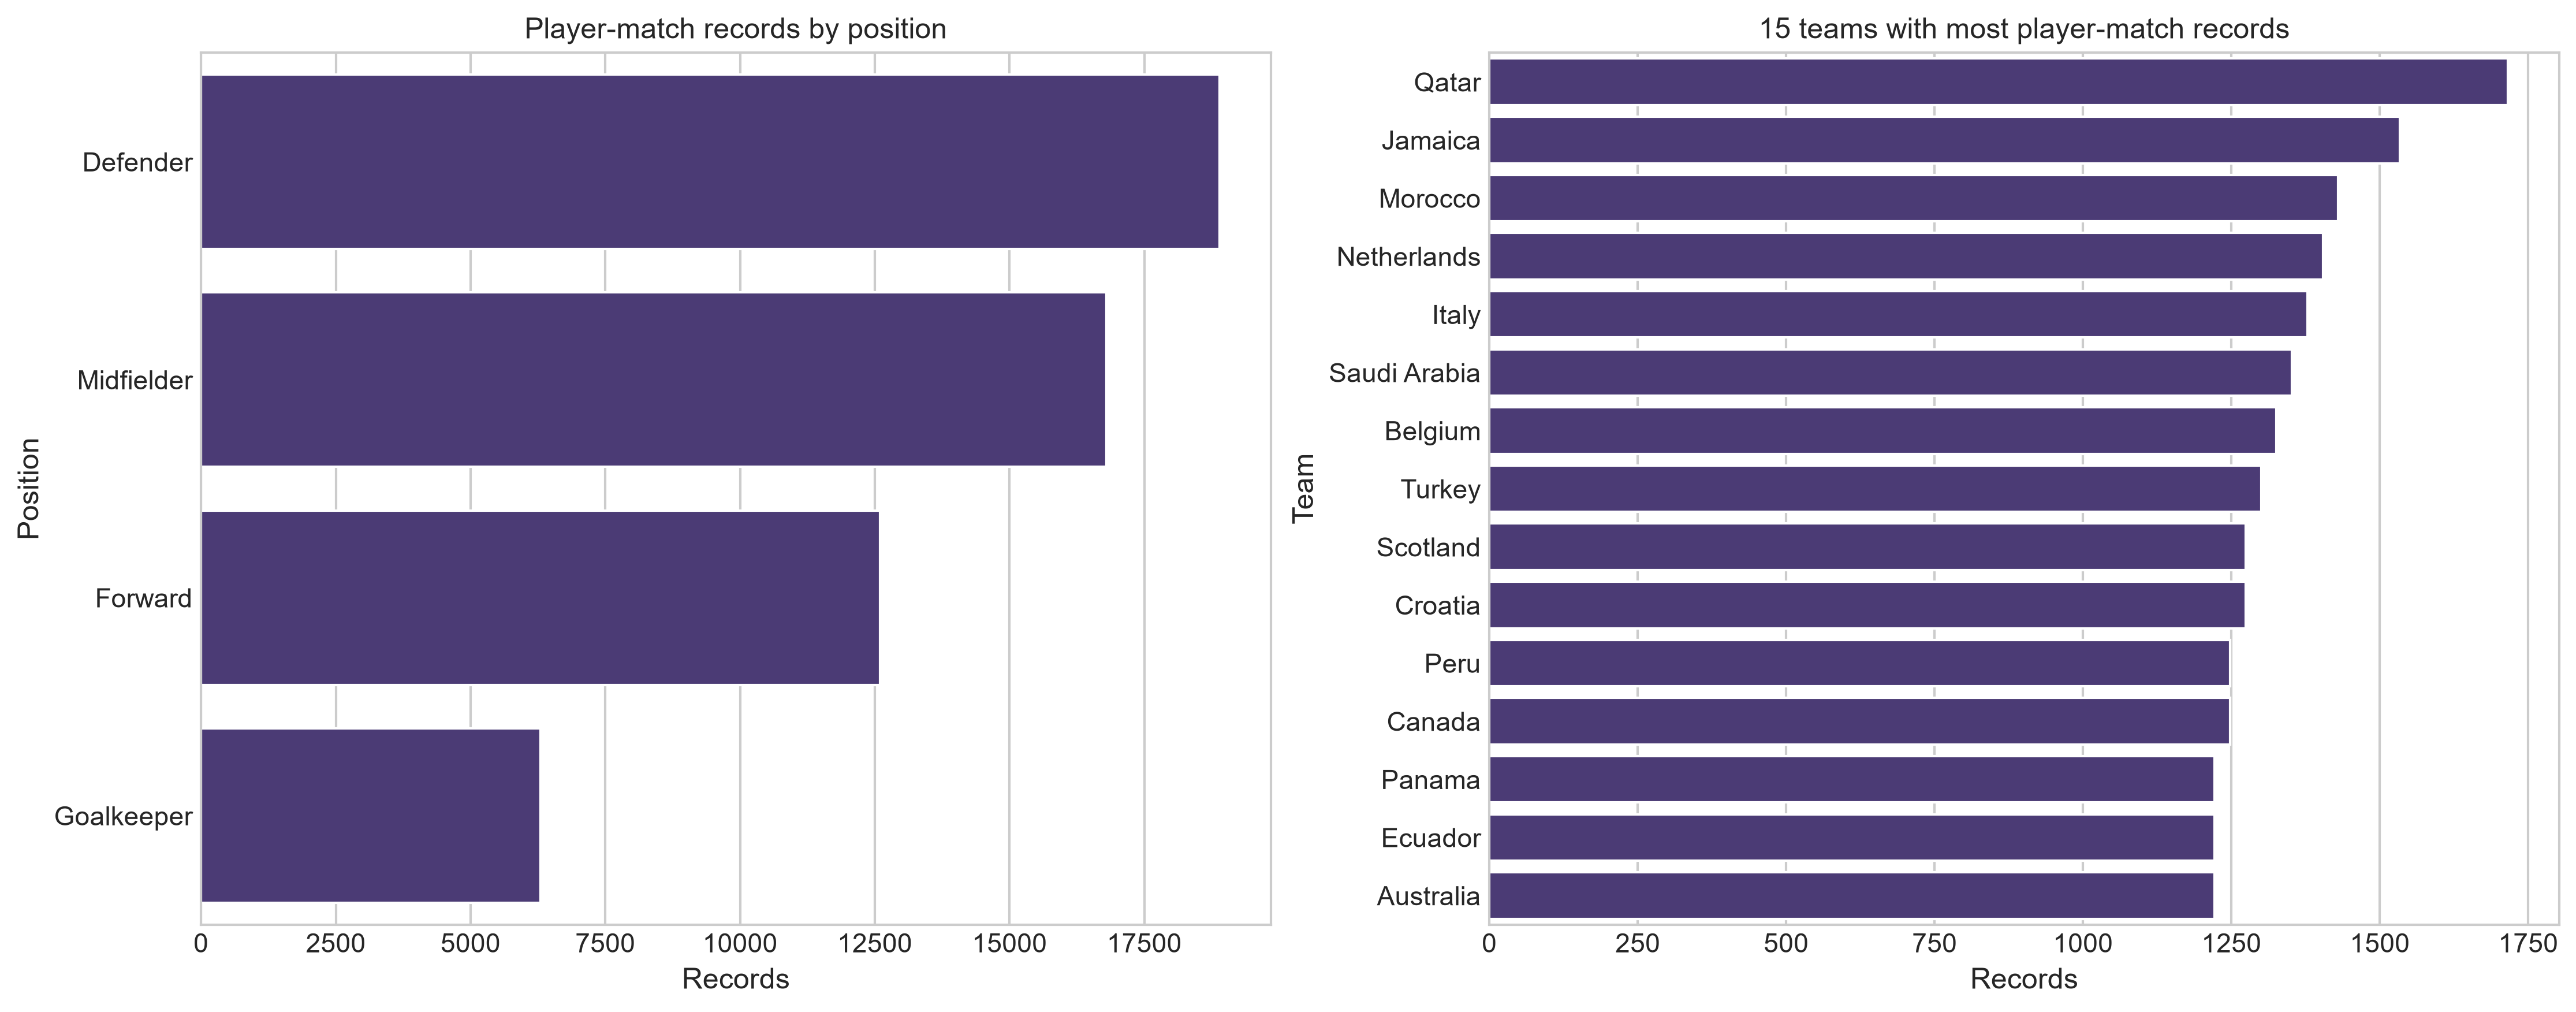

player_rating_distribution.png


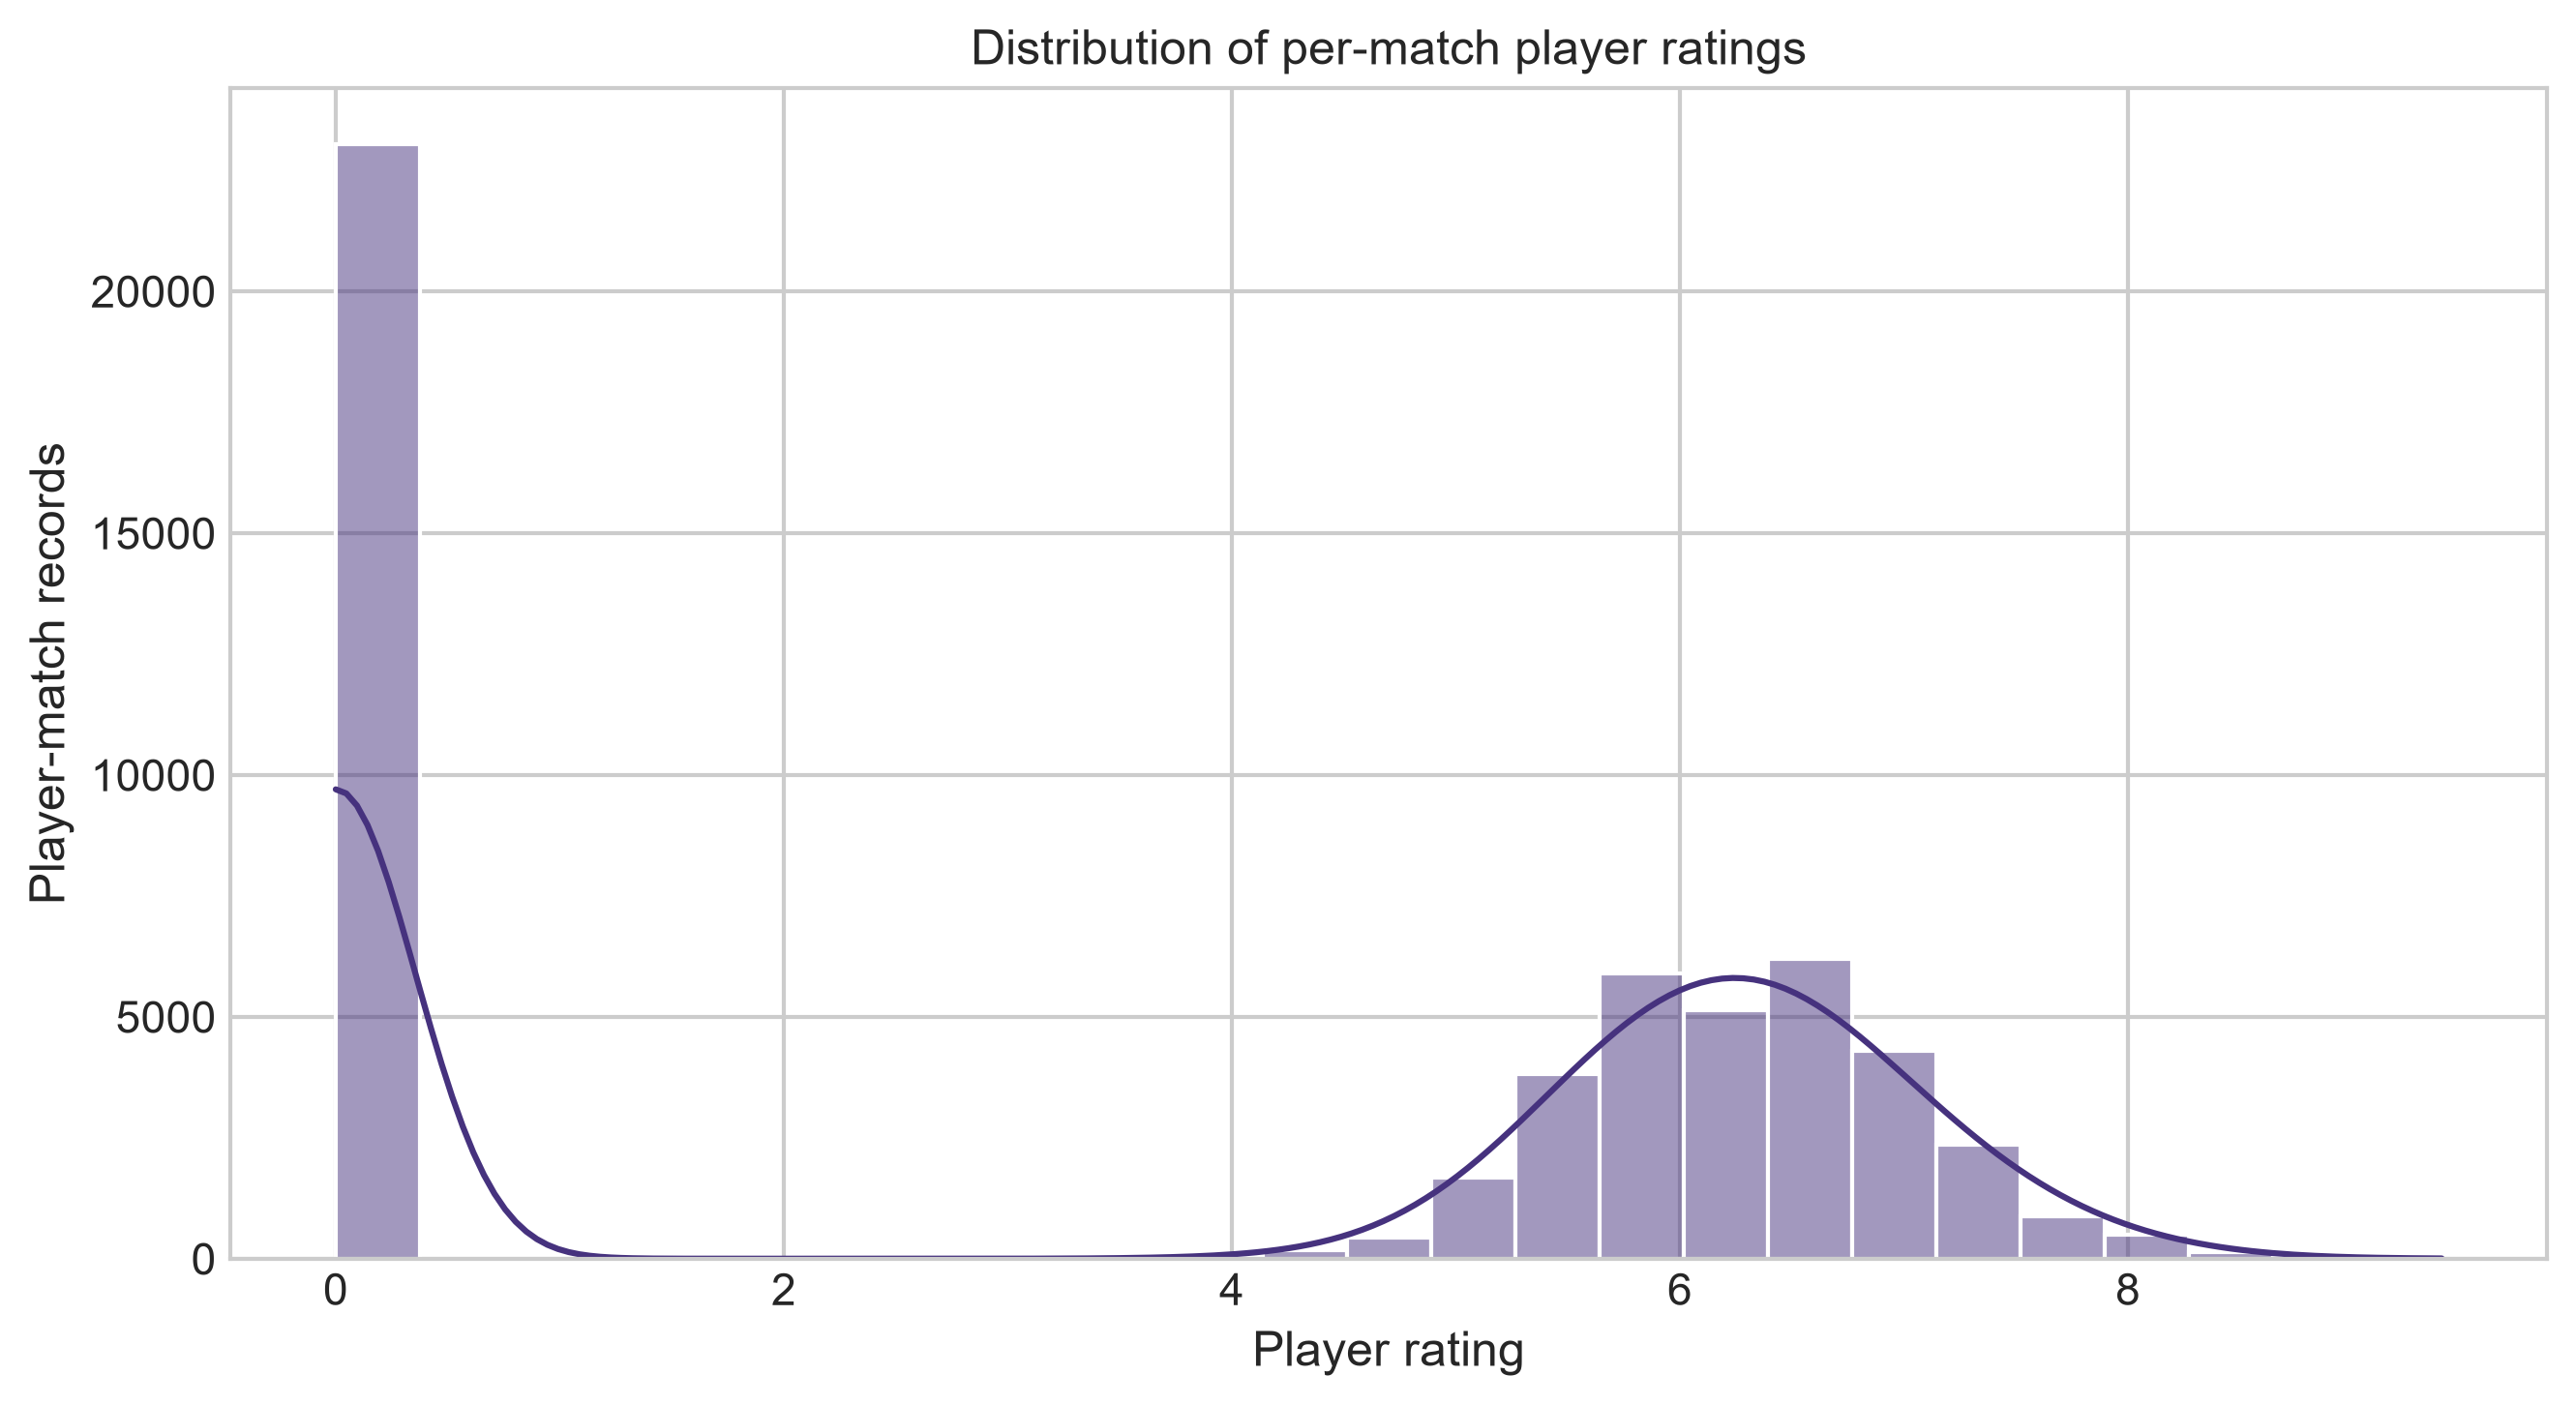

player_rating_by_position_boxplot.png


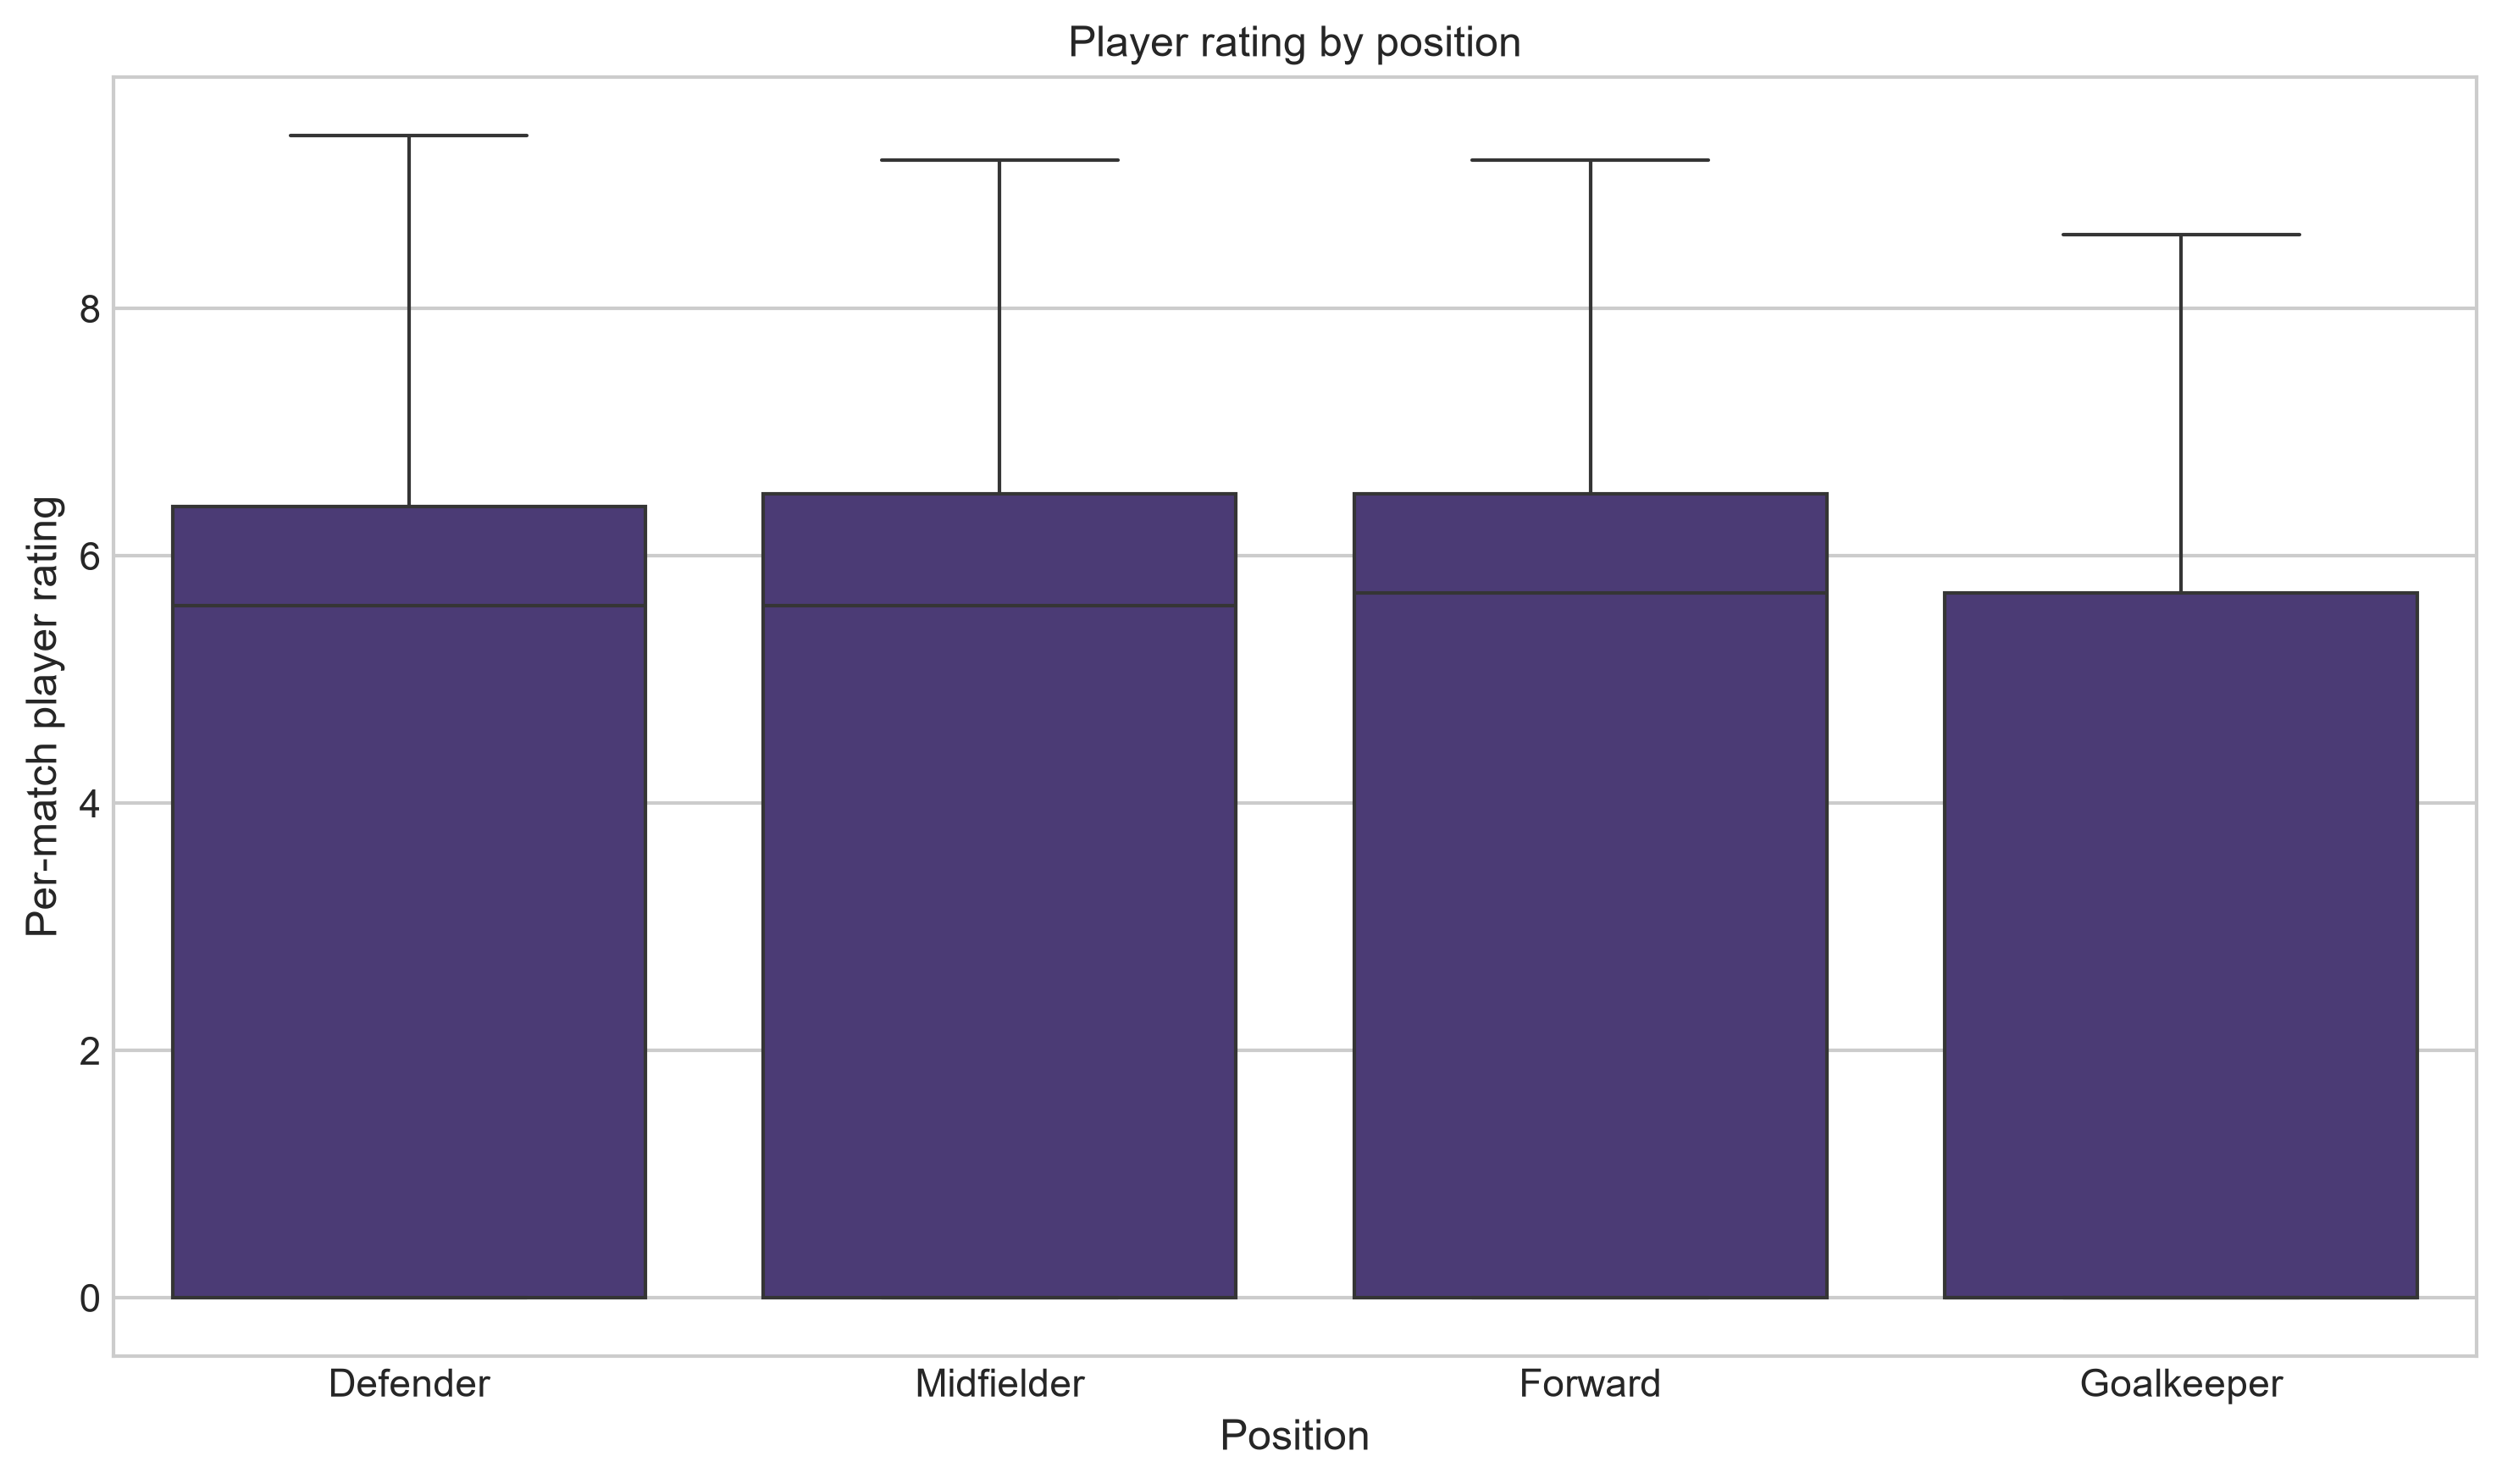

performance_by_position_violin.png


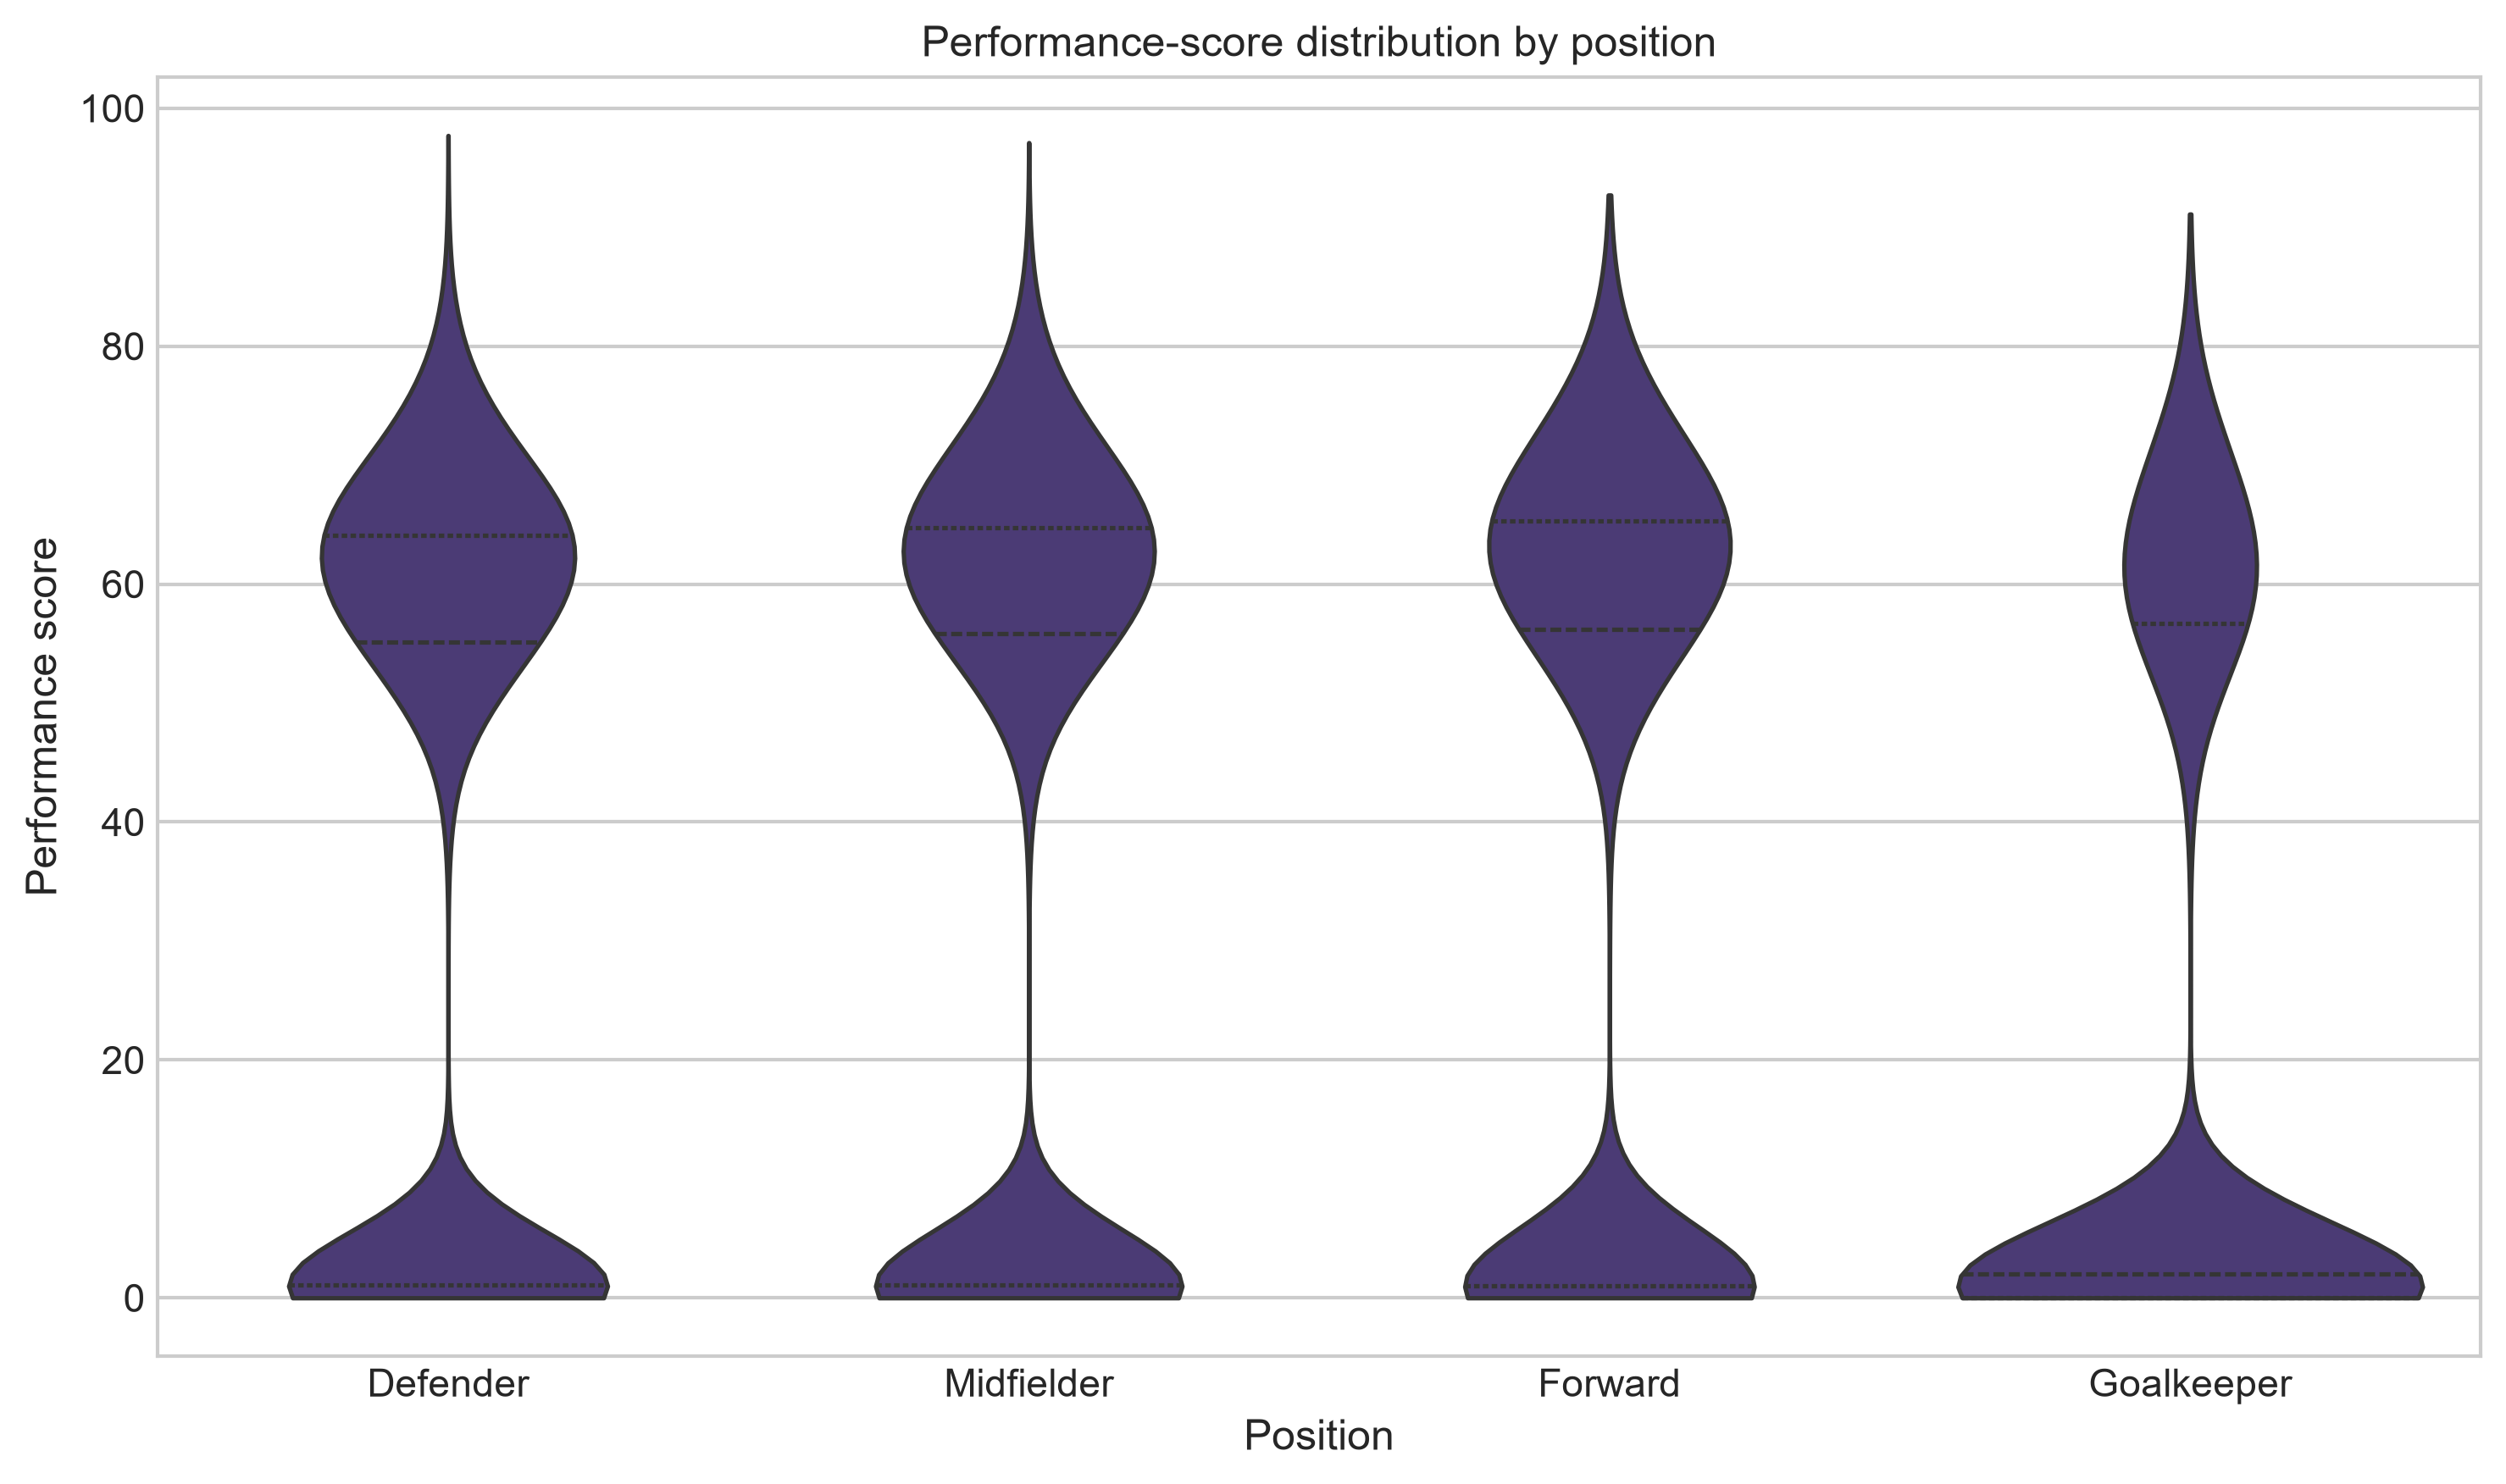

shots_vs_goals.png


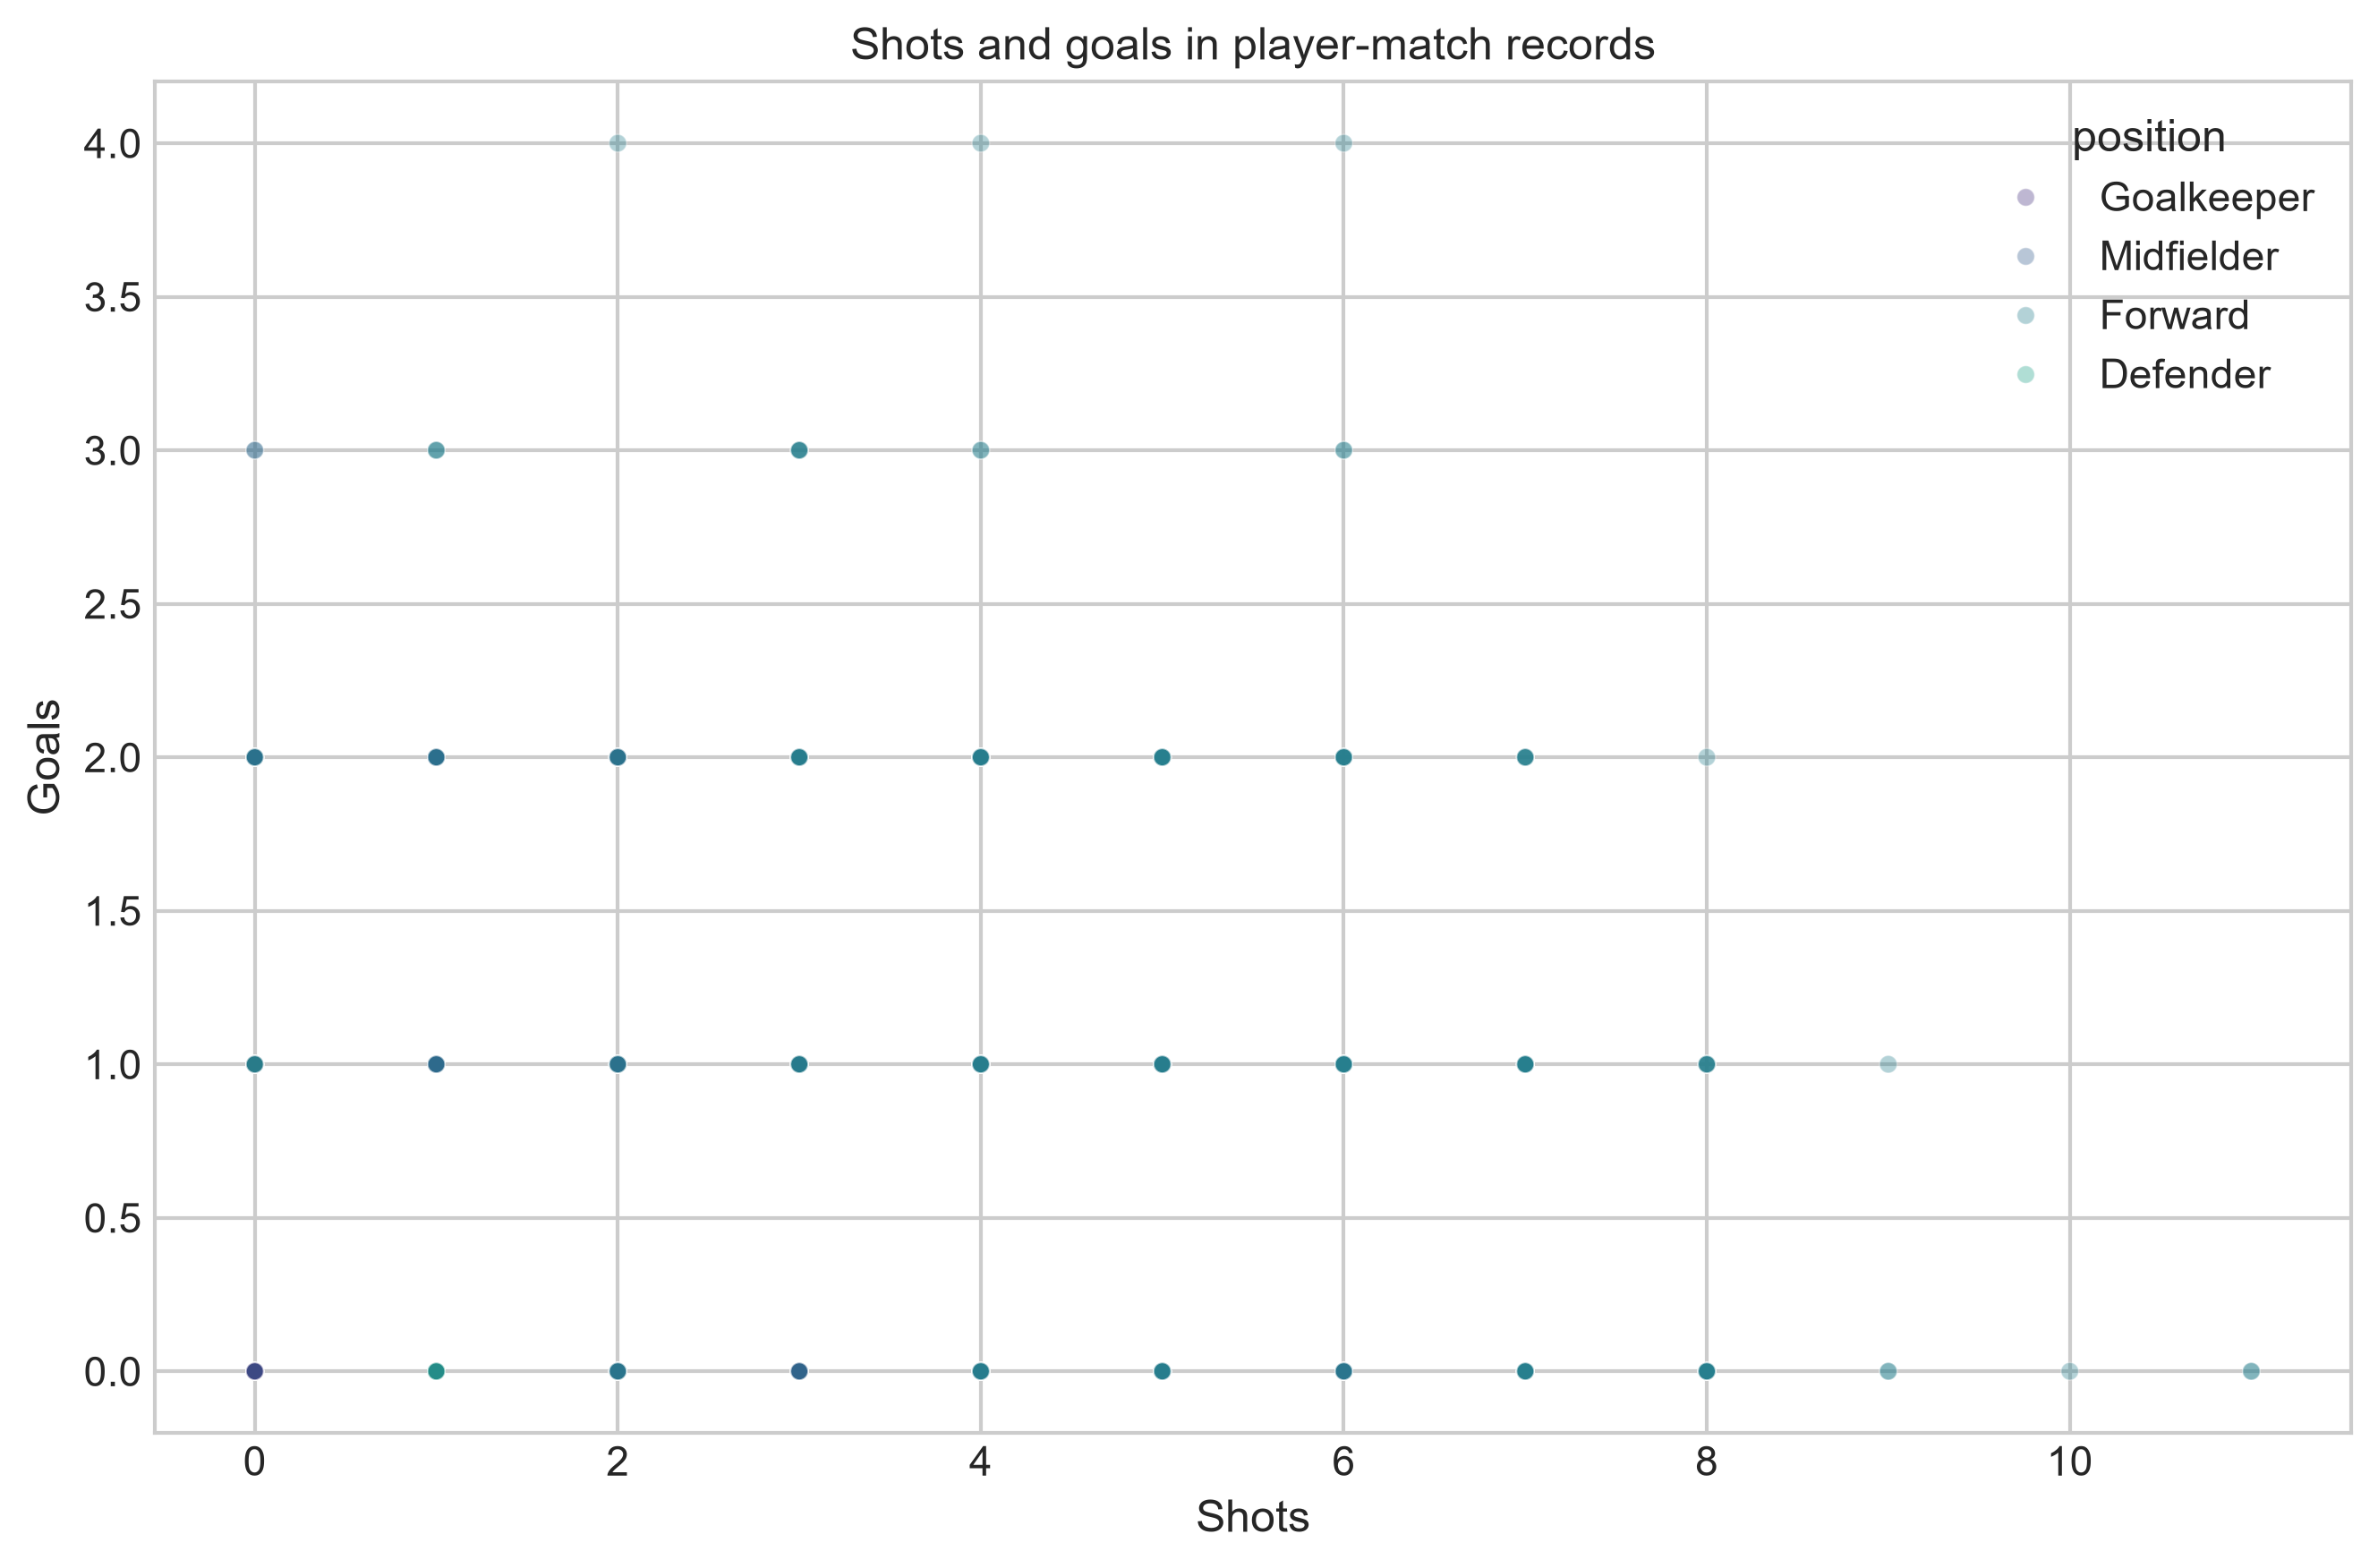

correlation_heatmap.png


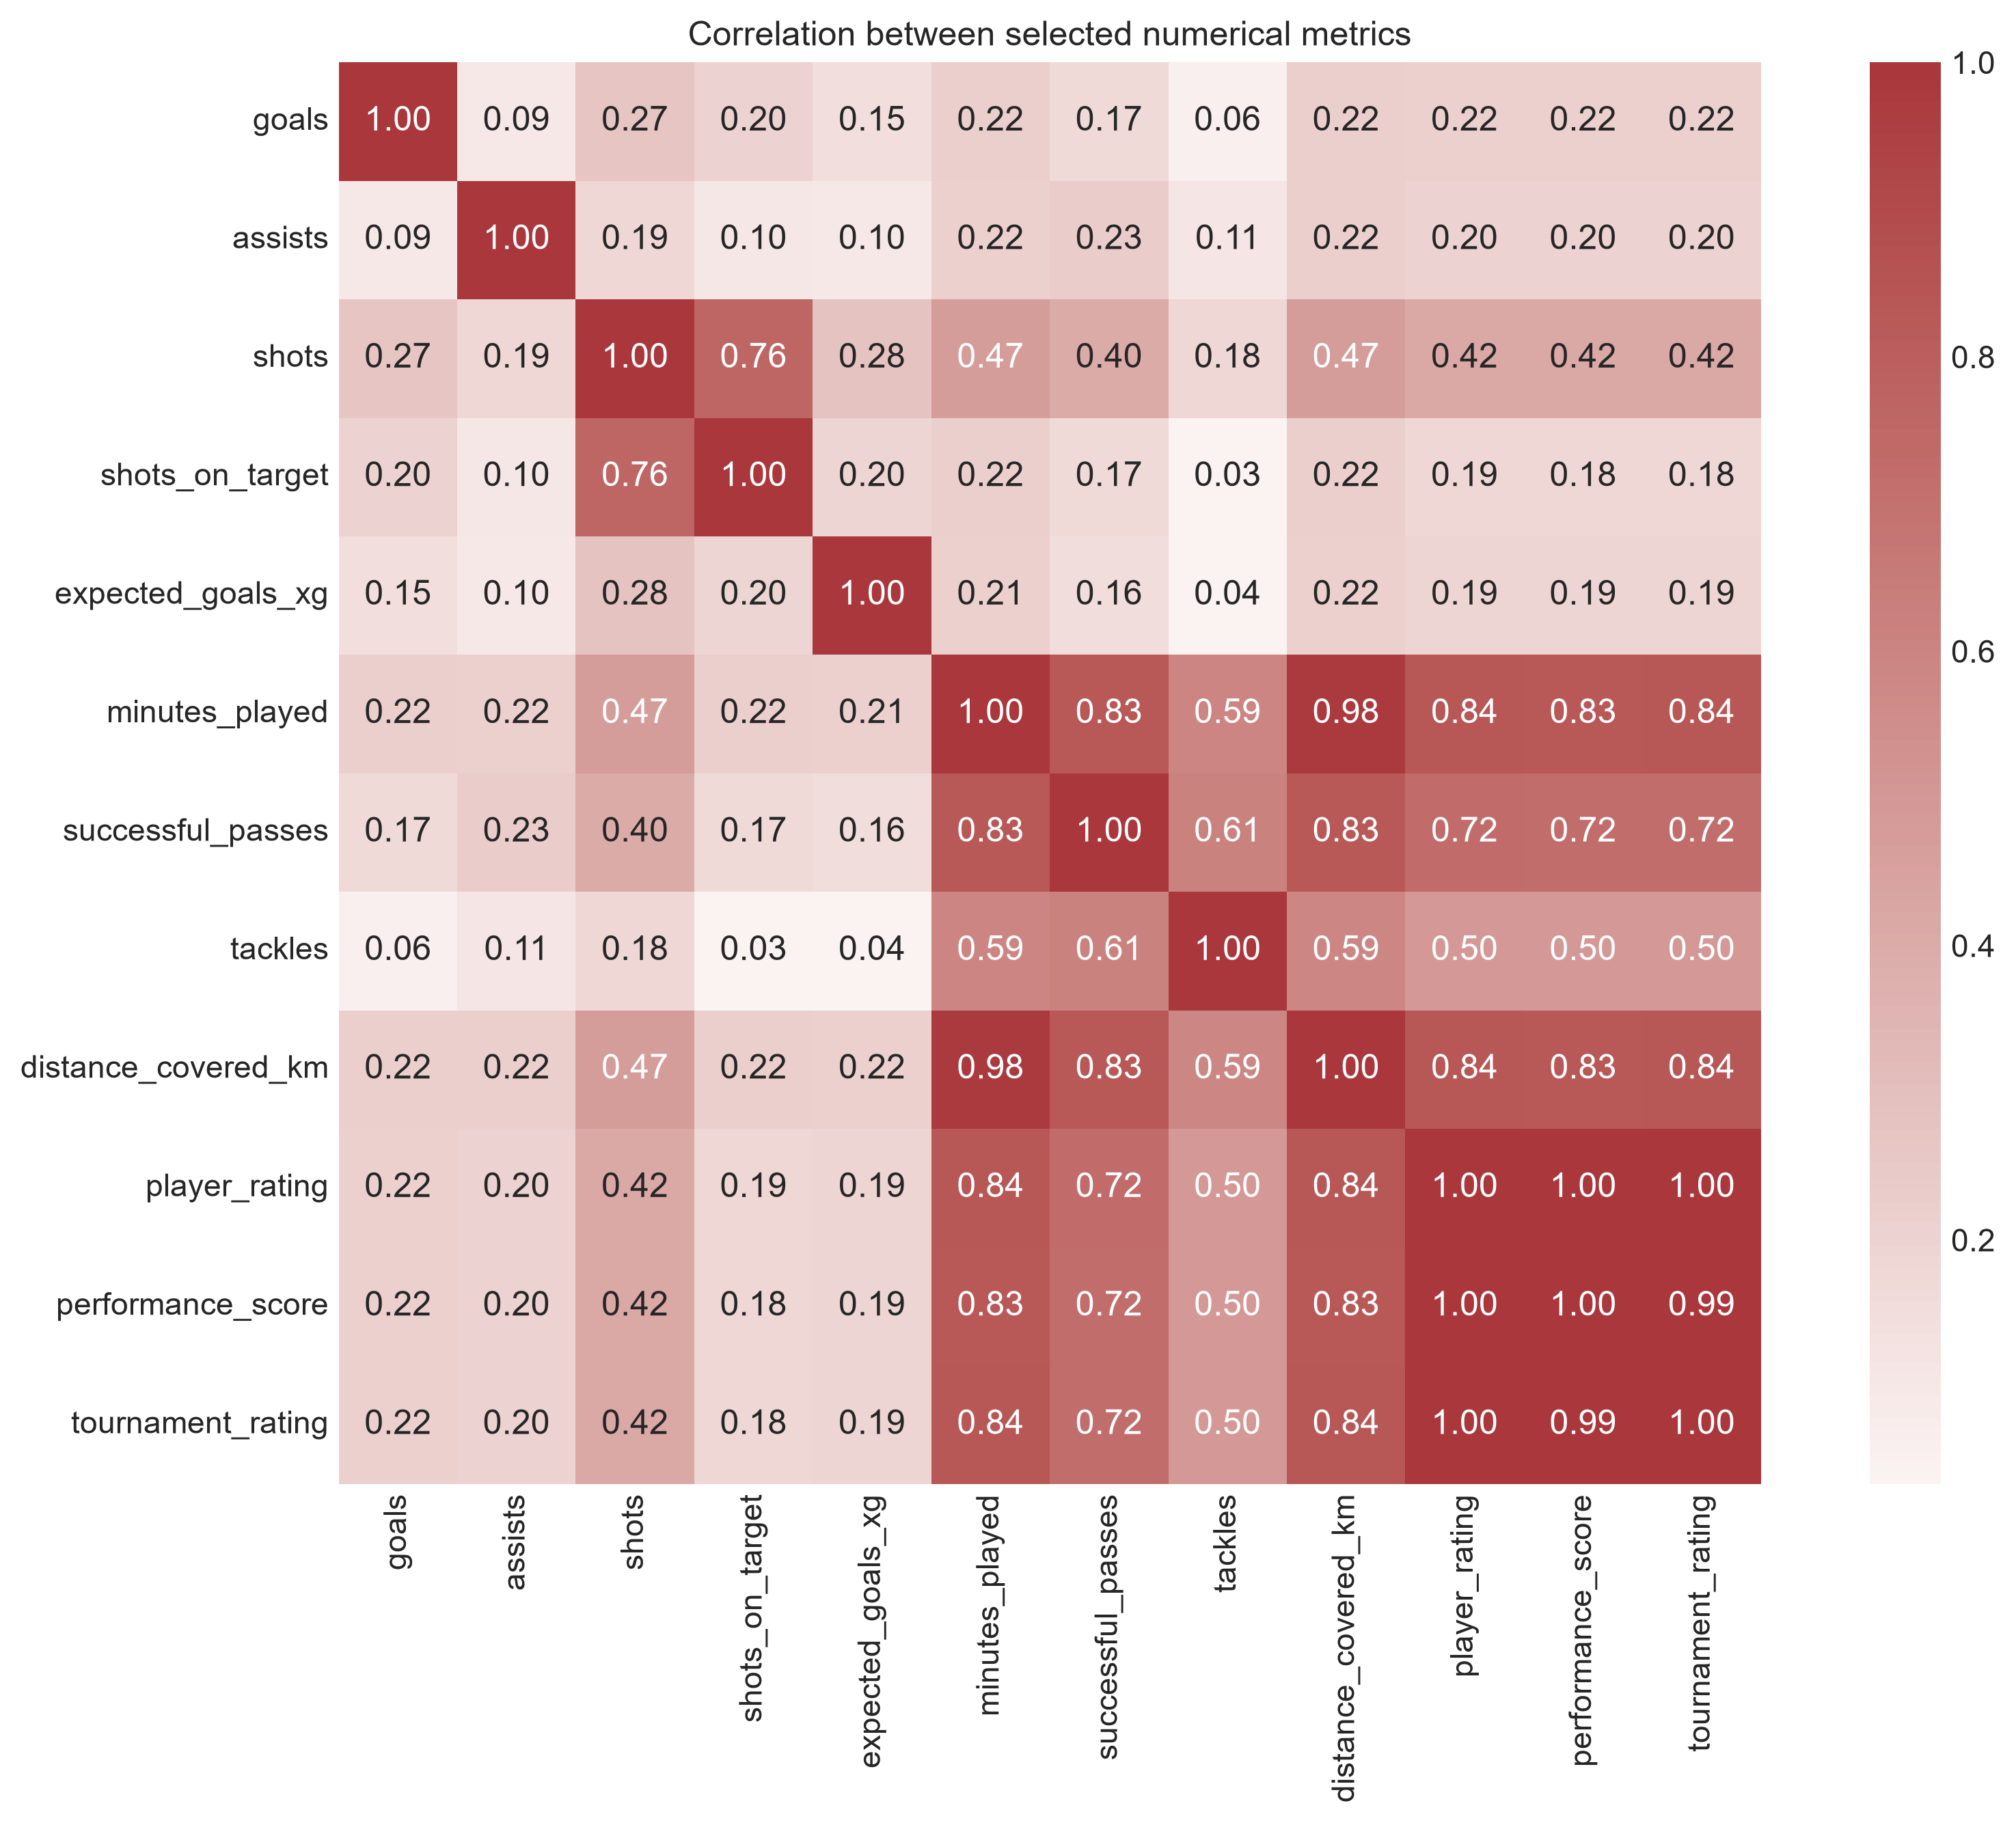

position_grouped_comparison.png


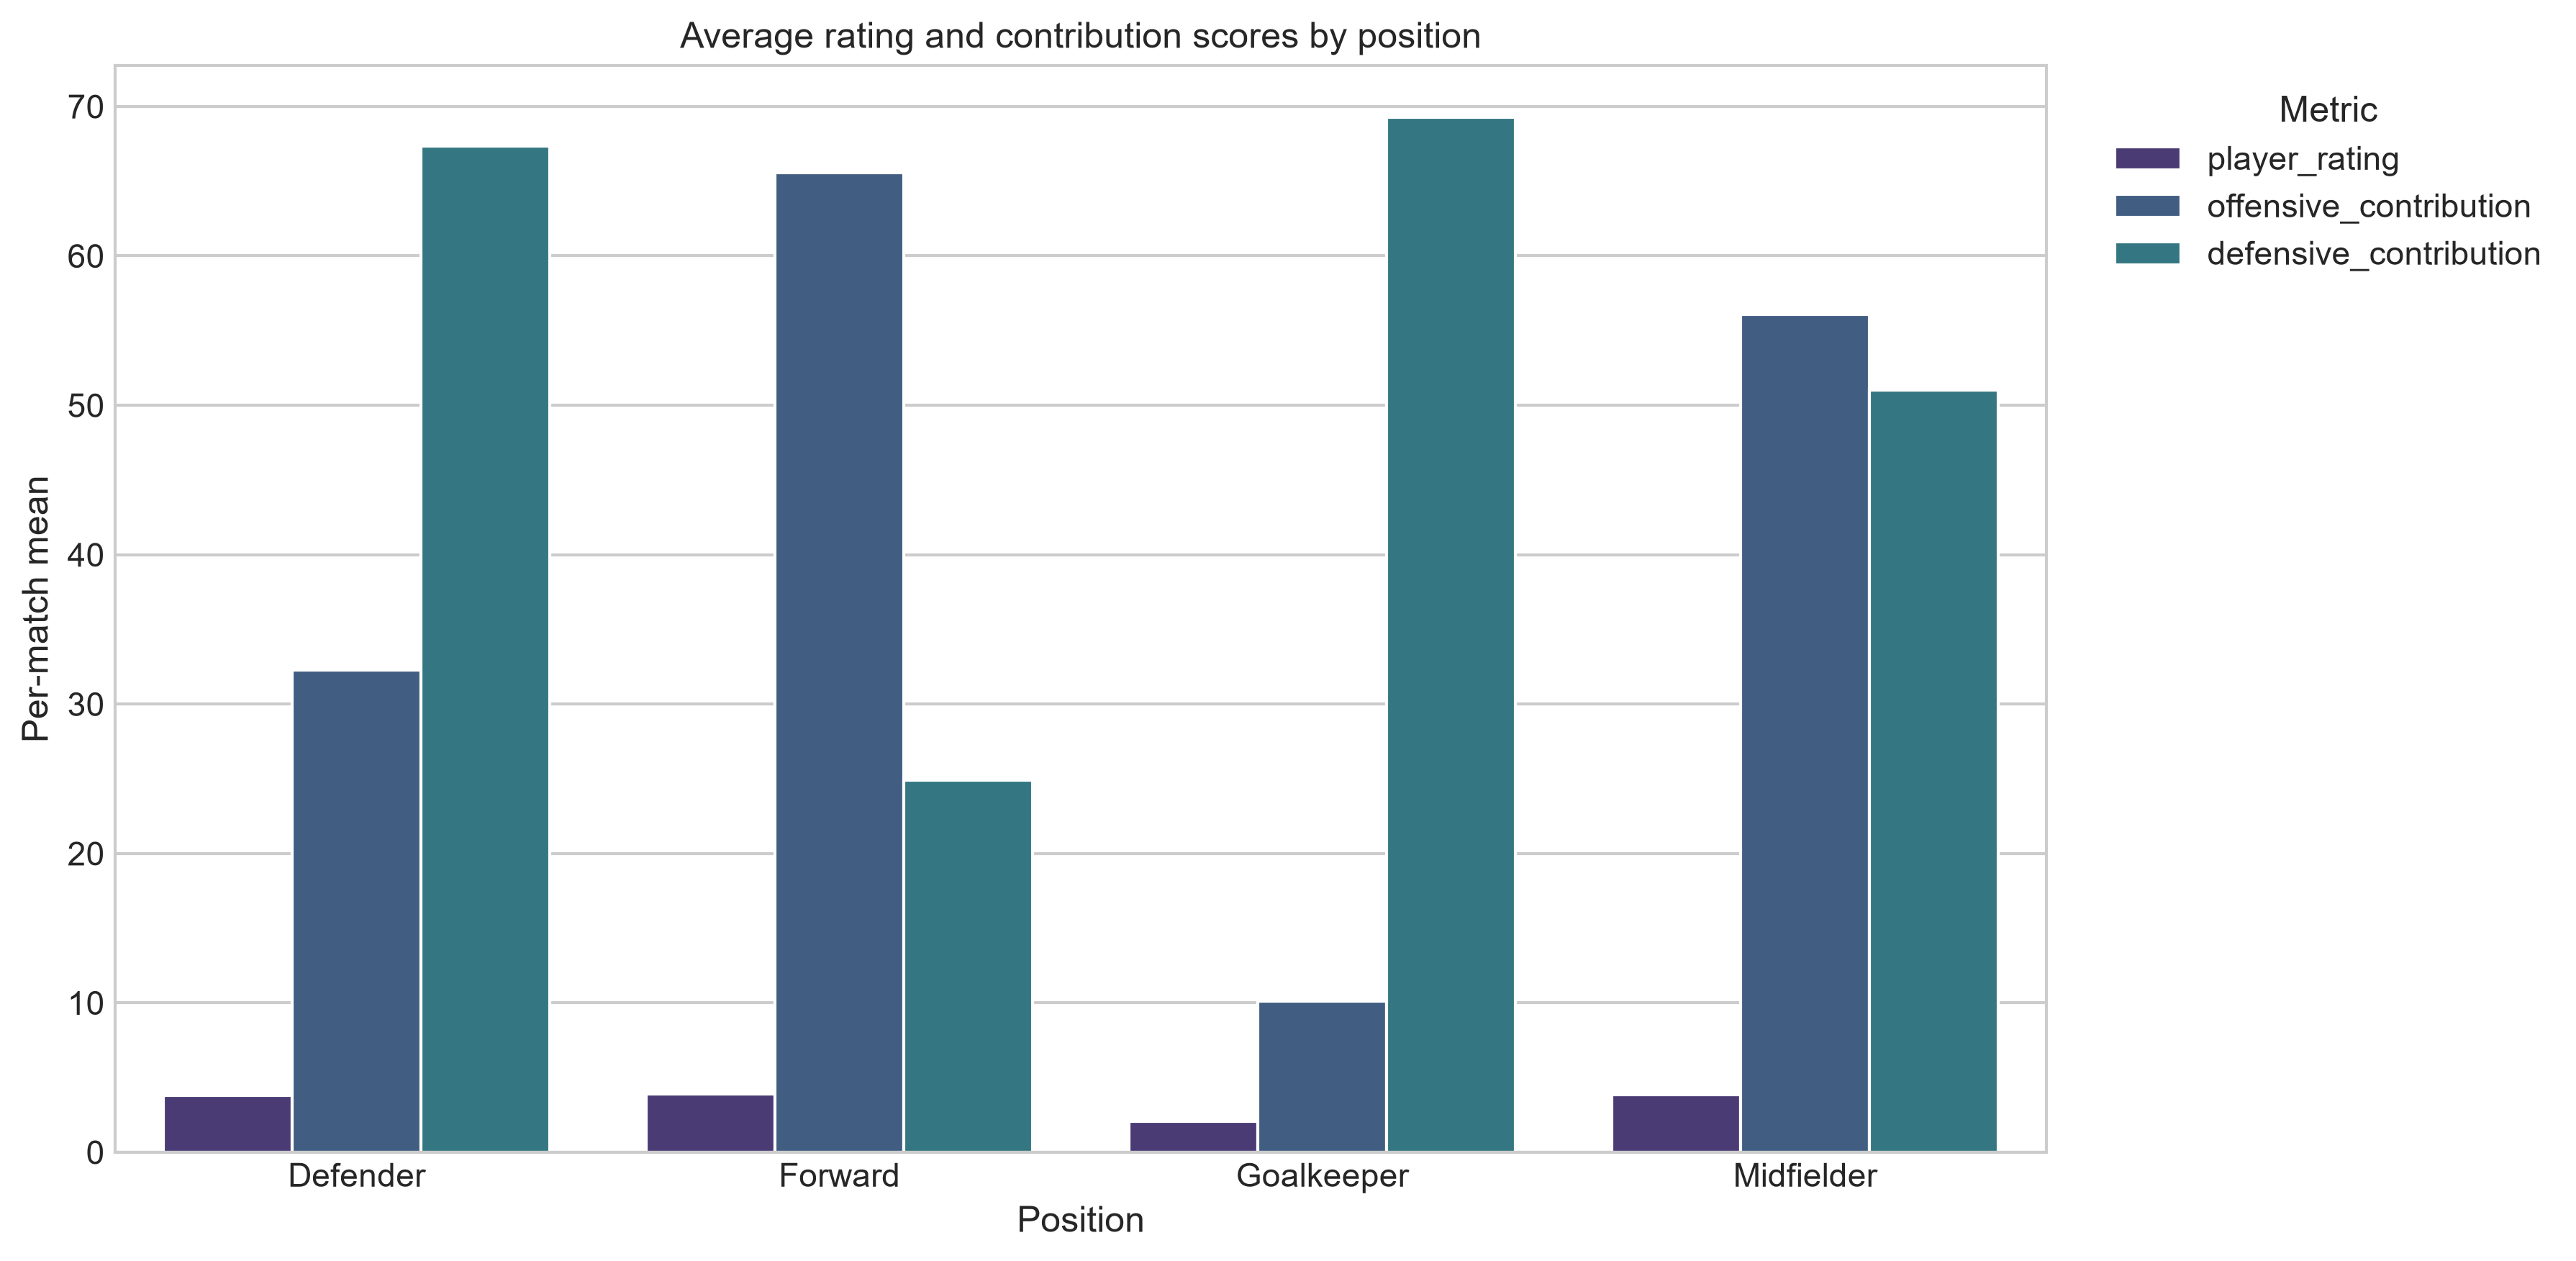

top_scorers.png


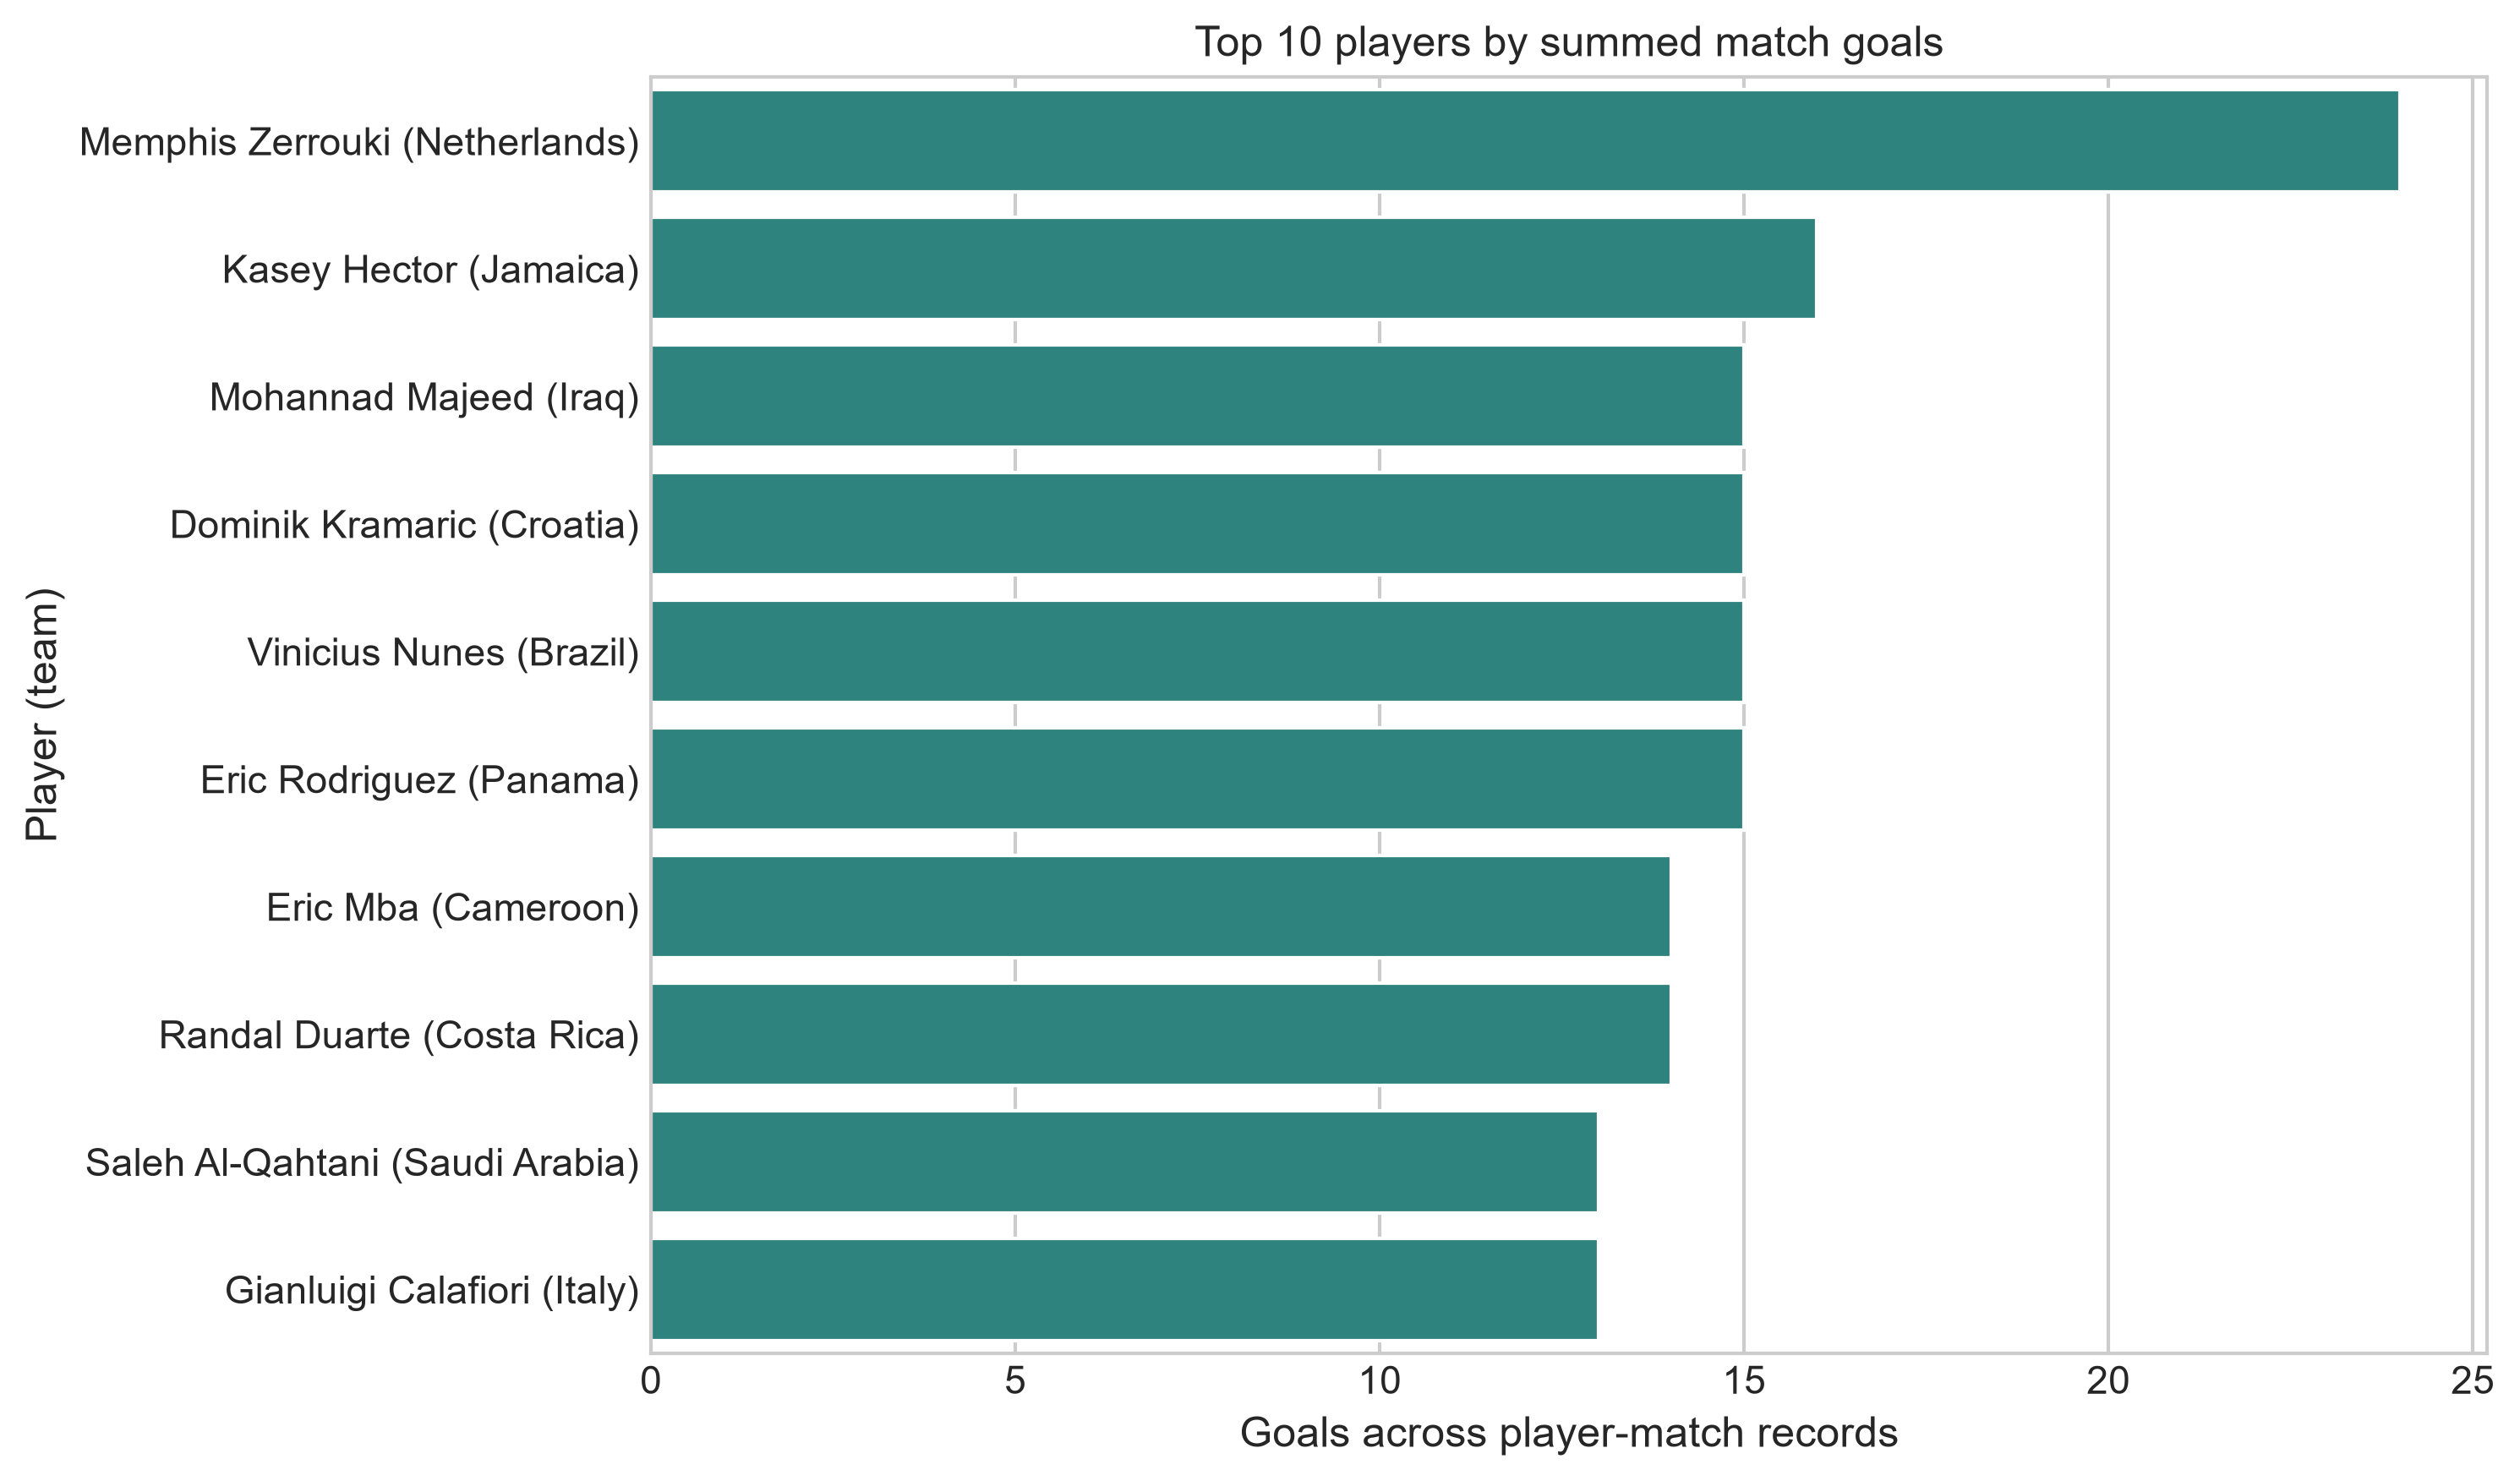

daily_player_goals.png


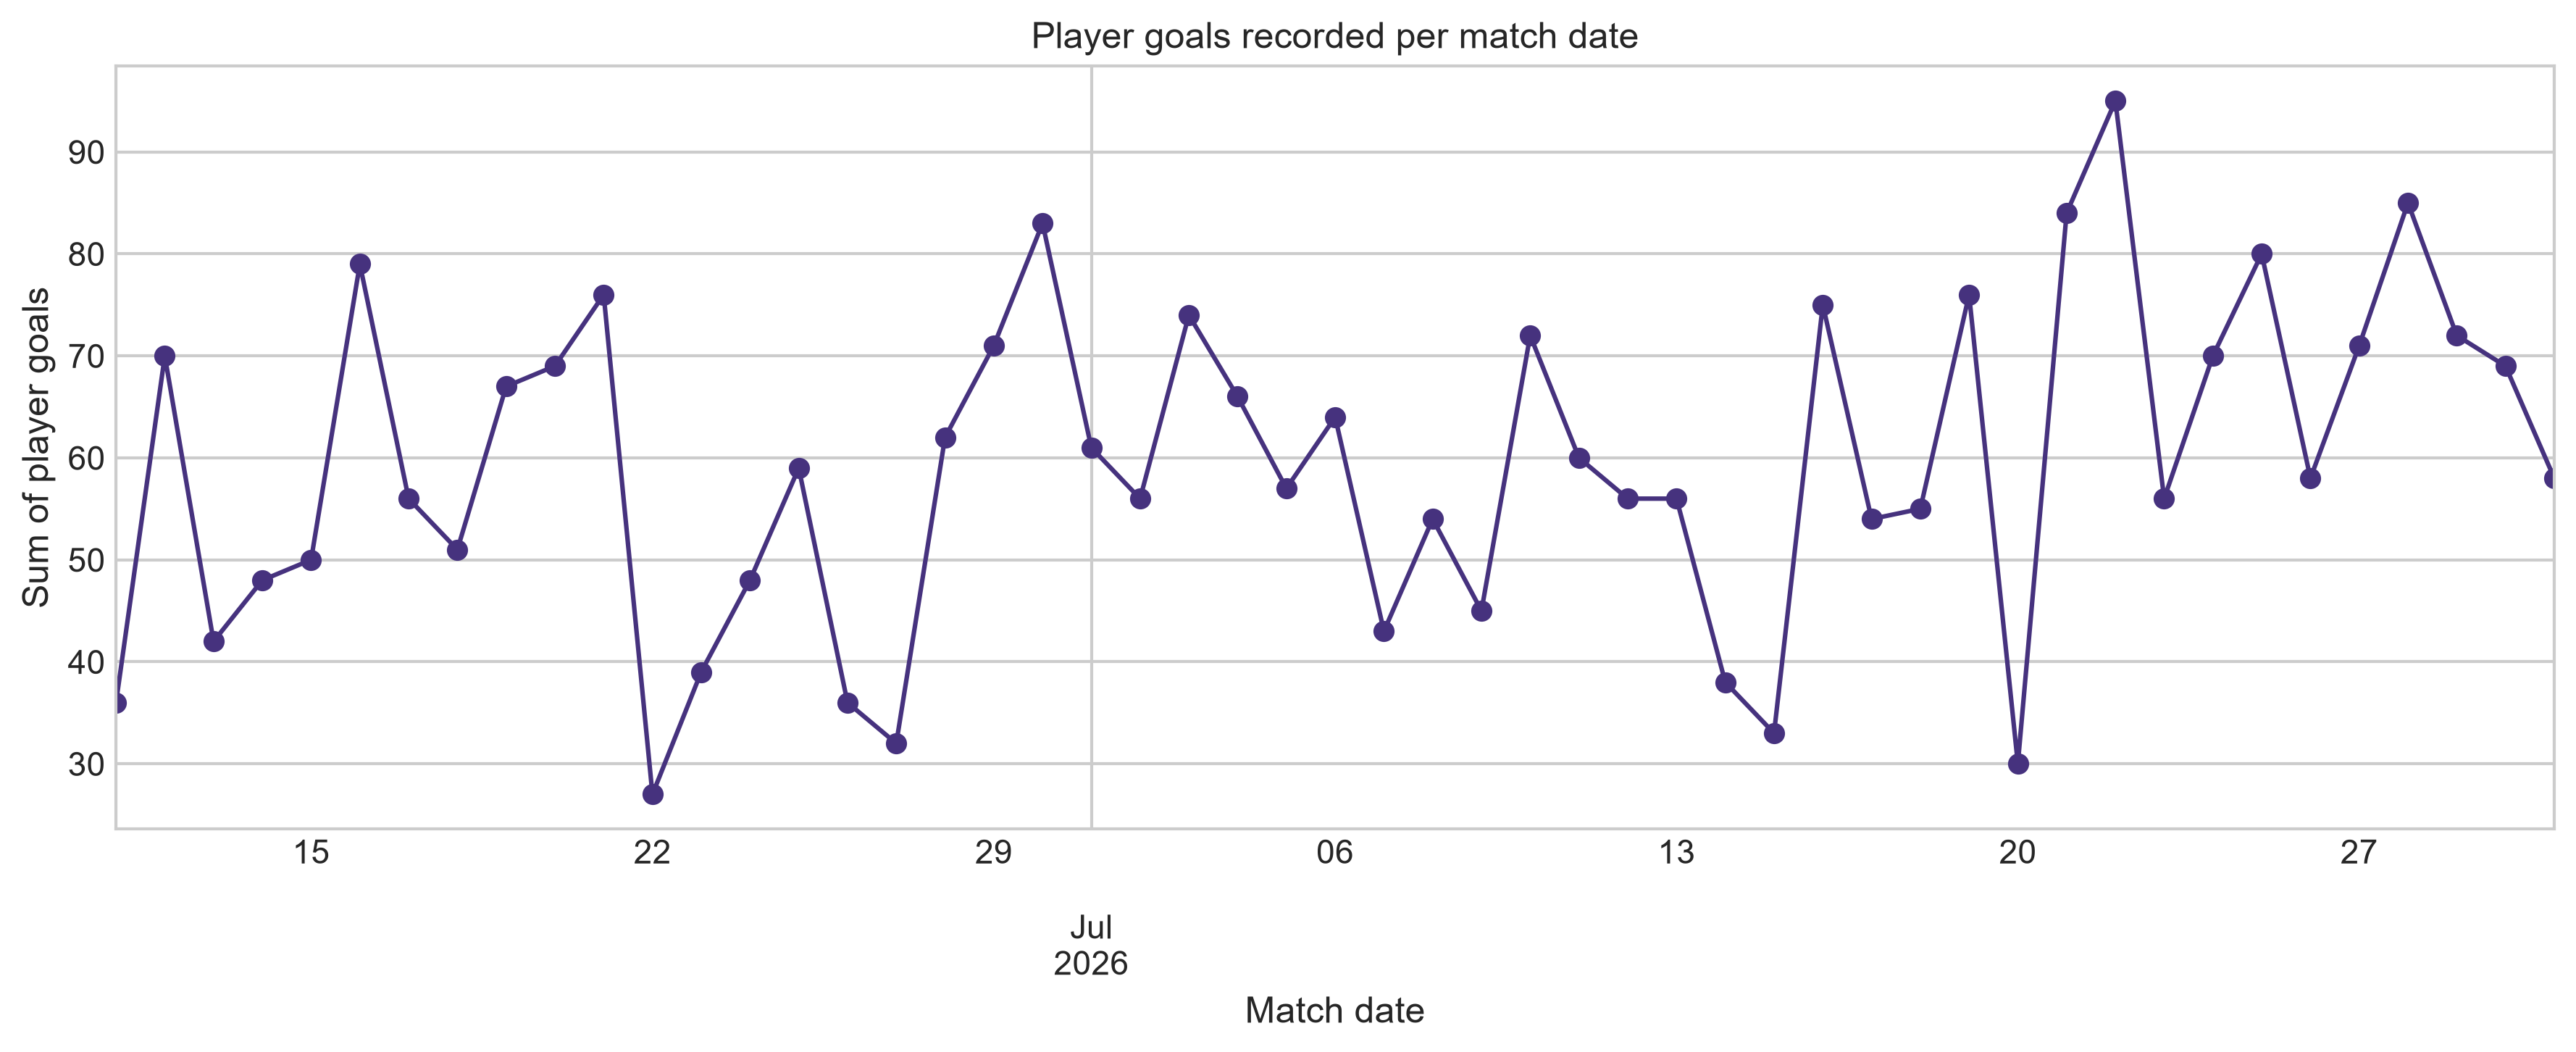

In [6]:
plot_files = save_figures(data, tables["player_rankings"], plots_path)
print(f"Saved {len(plot_files)} plots to {plots_path.relative_to(project_root)}")
for plot_file in plot_files:
    print(plot_file.name)
    display(Image(filename=str(plot_file)))

## 7. Findings and output files

In [7]:
for finding in describe_findings(
    data,
    tables["position_summary"],
    tables["player_rankings"],
    tables["outlier_summary"],
):
    display(Markdown(f"- {finding}"))

print("\nAnalysis tables:")
for table_file in sorted(tables_path.glob("*.csv")):
    print(table_file.relative_to(project_root))
print("\nGenerated figures:")
for plot_file in sorted(plots_path.glob("*.png")):
    print(plot_file.relative_to(project_root))

- The dataset contains 54,600 player-match records, 1,248 distinct player IDs, and 48 teams.

- The player with the most summed match goals is Memphis Zerrouki (Netherlands) with 24.

- Forward has the highest mean per-match player rating (3.88) among the listed positions.

- The IQR rule flags 2,743 records for goals; these are potential outliers, not confirmed errors.

- These are descriptive comparisons of the supplied records. Correlation and group averages do not establish causes, and team summaries are based on player-match records rather than match scores.


Analysis tables:
outputs\tables\category_frequencies.csv
outputs\tables\cleaning_report.csv
outputs\tables\column_info.csv
outputs\tables\correlations.csv
outputs\tables\missing_summary.csv
outputs\tables\numeric_summary.csv
outputs\tables\outlier_summary.csv
outputs\tables\player_rankings.csv
outputs\tables\position_summary.csv
outputs\tables\quality_checks.csv
outputs\tables\team_summary.csv

Generated figures:
outputs\plots\category_counts.png
outputs\plots\correlation_heatmap.png
outputs\plots\daily_player_goals.png
outputs\plots\performance_by_position_violin.png
outputs\plots\player_rating_by_position_boxplot.png
outputs\plots\player_rating_distribution.png
outputs\plots\position_grouped_comparison.png
outputs\plots\shots_vs_goals.png
outputs\plots\top_scorers.png


## Interpretation notes

- Means and correlations describe patterns in these records; they do not establish cause and effect.
- IQR outliers are retained. Unusual values may represent rare performance, data-generation choices, or errors and require context to distinguish.
- Categorical counts are player-match record counts, not necessarily unique people or official roster sizes.
- The original CSV remains unchanged. Rerunning the notebook regenerates the cleaned copy, CSV tables, and PNG figures.